# **OPIM-5671 Team Project #2: *Coming Clean — What Toronto Airbnb Reviews Reveal***

- **Instructor:** Jaeung Sim (University of Connecticut)
- **Course:** OPIM 5671 Data Mining and Time Series Forecasting (Fall 2026)
- **Team Seven Members:** Matthew Koh, Preshitha Sureshkumar, James Eastwood, Rama Akach, Kaan Ates Boyaci, Luke Bauer
- **Dataset:** [Inside Airbnb: Toronto (Sep 2026)](https://www.kaggle.com/datasets/vladimirkondratev/inside-airbnb-toronto-sep-2026) (`vladimirkondratev/inside-airbnb-toronto-sep-2026`)
- **Last Updated:** November 9, 2026

---

### **1. Executive Summary & Research Questions**

Airbnb's platform displays aggregate star ratings that are heavily compressed near the 5-star ceiling (see the Toronto rating distribution in Section 1.4), alongside a simple single-word tag search. Because of rating inflation and survivorship bias, static star scores often obscure critical operational failures, property deterioration over time, and the nuanced interplay between host hospitality and physical accommodation quality.

Following our **Team Seven Proposal (*Coming Clean — What Toronto Airbnb Reviews Reveal*)** and the **OPIM-5671 Team Project #2 Guidelines**, this notebook investigates one primary research question and two follow-up questions:

1. **Primary Research Question (Themes & Dissatisfaction):** *What themes appear in Toronto Airbnb guest reviews, and which are most common in reviews expressing dissatisfaction?*
2. **Longitudinal Property Trajectory Question (Reviews Changing Over Time):** *When linking individual guest reviews chronologically to specific properties (`listing_id`) from 2010 to 2026, how do review sentiment and complaint themes evolve over time to expose deteriorating properties versus turnaround properties that static cumulative ratings mask?*
3. **The "Michelin Star" Host Interaction Question:** *How relevant is a guest's personal interaction with the host (measured via normalized `host_name` mentions in text and communication ratings) to the overall rating and sentiment of an Airbnb listing compared to physical property attributes (cleanliness, accuracy, location, and value)?*

**Primary method:** LDA topic modeling on review word counts (with TF–IDF as the supporting representation). **Supporting analysis:** comparisons across groups (dissatisfied vs. satisfied reviews, host mentioned vs. not) and over time (early vs. recent reviews of the same listing), validated with representative review texts. All findings are observed associations, not causal effects.

---

### **2. Intended Decision-Makers & Practical Value**

| Decision-Maker | Key Decision / Problem | How Text-Mining Findings Inform Action |
|---|---|---|
| **Airbnb (Platform Quality & Trust)** | *Based on complaints, which listings are bad or deteriorating over time? How can we improve listing quality and search filters?* | Use rolling recent-review complaint signals (`not_clean`, `not_work`, `smell`, `stain`) per `listing_id` to flag listings whose recent reviews diverge from their lifetime star average. |
| **Hosts (Property Operations)** | *Based on customer sentiment, is my listing good or bad? What should I fix first?* | Prioritize the unit-operations issues (bathroom, bed, kitchen, cleanliness) that dominate dissatisfied reviews, set accurate expectations in the listing, and keep host communication personal and responsive. |
| **Customers / Guests (Booking Decisions)** | *Based on glowing reviews vs. hidden text complaints, where are the genuinely good listings?* | Look beyond 4.7+ lifetime averages by inspecting recent chronological reviews for negation-bound complaint tokens and multi-unit commercial host red flags. |

---

### **3. Alignment with Team Seven's 10-Step Analytical Plan & Course Guidelines**

| Proposal Step | Analytical Task | Implementation in This Notebook |
|---:|---|---|
| **Step 1** | **Preprocessing (English-only executive decision)** | Section 1: Strip HTML `<br/>` artifacts, drop missing/duplicate texts, and apply an approximate rule-based English filter (dropping 77,107 reviews flagged as non-English rather than machine-translating). |
| **Step 2** | **Join `host_name` and `listing_ratings` by `listing_id`** | Section 1 & Section 6: Inner-join `reviews.csv` (`729,202` rows) with `listings.csv` (`22,050` listings, of which `17,764` have reviews) on `listing_id == id` to link every review to property ratings, neighbourhood, Superhost status, and longitudinal timelines. |
| **Step 3** | **Bag-of-Words representation** | Section 3 & Section 5: Construct sparse document–term count matrices (`CountVectorizer`) fitted strictly on training data. |
| **Step 4** | **Tokenize, replace `host_name` with generic token, & anonymize `reviewer_name`** | Section 1 & Section 2: Drop `reviewer_name` for privacy; replace each listing's `host_name` into a unified `host_name_token` and track `mentions_host_name`. |
| **Step 5** | **Flag stop words that flip sentiments with valuable tokens** | Section 2 & Section 4: Preserve raw text for `TextBlob` polarity; bind sentiment-flipping negations (`not`, `no`, `never`, `n't`) to content lemmas (`not_clean`, `not_work`, `not_recommend` vs. litotes `not_disappoint`, `not_hesitate`). |
| **Step 6** | **Remove unnecessary stop-words** | Section 2: Remove standard English and domain-boilerplate stopwords (`airbnb`, `toronto`, `stay`, `place`) and compare top 20 token frequencies before vs. after filtering. |
| **Step 7** | **Lemmatization & `host_name` nickname resolution** | Section 2: Apply POS-aware `WordNetLemmatizer` and map 40+ common English nickname families (*Alexandra ↔ Alex*, *Michael ↔ Mike*, *Matthew ↔ Matt*) to `host_name_token`. |
| **Step 8** | **Calculate TF, IDF, then TF–IDF (+ Truncated SVD)** | Section 3: Compute explicit $\text{TF}$, $\text{IDF}$, and $\text{TF–IDF}$ tables, contrast dissatisfied vs. satisfied TF–IDF terms, and extract 10 `TruncatedSVD` components. |
| **Step 9** | **Perform LDA Topic Modeling** | Section 5: Fit `LatentDirichletAllocation` across $K \in \{2, 3, 4\}$ on training word counts, evaluate **UMass Coherence**, and validate topic labels with representative reviews. |
| **Step 10** | **Cross-analyze TF–IDF with LDA, Sentiment/Emotions, Time Trajectories, & Prediction** | Sections 5, 6, & 7: Cross-tabulate LDA topics with TF–IDF, `TextBlob` polarity, `NRCLex` emotions, longitudinal property drift, the Michelin Star host question, and Train/Validation/Test regression models (`MAE`, `MSE`, $R^2$). |


## **0. Colab Setup, Reproducibility Constants, and Helper Functions**

This notebook runs end-to-end on Google Colab's free CPU runtime or a standard local Python environment. In accordance with course guidelines (`04_Quantifying_Texts`, `05_Text_Features_and_Rating_Prediction`, and `Assignment #2`), we use lightweight, reproducible libraries (`kagglehub`, `nltk`, `textblob`, `nrclex`, `scikit-learn`), fix `SEED = 25`, and print package versions for full reproducibility.


In [1]:
# Install lightweight dependencies if missing (compatible with both Google Colab and local Jupyter)
import importlib.util, subprocess, sys
for pkg_spec, mod_name in [('kagglehub', 'kagglehub'), ('nltk', 'nltk'), ('textblob==0.19.0', 'textblob'), ('nrclex==4.1.0', 'nrclex')]:
    if importlib.util.find_spec(mod_name) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg_spec])


In [2]:
import os, re, time, random, warnings, importlib.metadata
from pathlib import Path
from collections import Counter
from itertools import chain

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from textblob import TextBlob
from nrclex import NRCLex

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110

# Reproducibility and runtime bounds aligned with OPIM 5671 notebooks
SEED = 25
random.seed(SEED)
np.random.seed(SEED)

MAX_REVIEWS = 3000        # Stratified working sample for full NLP & predictive modeling
TOPIC_FIT_LIMIT = 1500    # Training subset cap for LDA fitting
TOPIC_WORD_LIMIT = 150    # Per-review token cap for topic modeling
MAX_TERMS = 2000          # Vocabulary cap for TF-IDF representation
MAX_COMPONENTS = 10       # Truncated SVD components
TOPIC_COUNTS = (2, 3, 4)  # Candidate topic numbers K evaluated via UMass coherence

EMOTIONS = ['anger', 'fear', 'anticipation', 'trust', 'surprise', 'sadness', 'joy', 'disgust']
EMOTION_COLS = [f'{e}_per100' for e in EMOTIONS]

pd.set_option('display.max_colwidth', 120)
for package in ['numpy', 'pandas', 'scikit-learn', 'nltk', 'textblob', 'nrclex']:
    print(f'{package:15s}: {importlib.metadata.version(package)}')


numpy          : 2.1.3
pandas         : 2.2.3
scikit-learn   : 1.9.1
nltk           : 3.10.4
textblob       : 0.19.0
nrclex         : 4.1.0


In [3]:
# Download required NLTK lexical resources (stopwords and WordNet lemmatizer)
for resource in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(resource, quiet=True, raise_on_error=True)

# Course-standard helper functions for LDA inspection, UMass coherence, and regression evaluation
def top_words(model, vectorizer, n=10):
    terms = vectorizer.get_feature_names_out()
    return {f'Topic_{i+1}': list(terms[row.argsort()[-n:][::-1]])
            for i, row in enumerate(model.components_)}

def umass_coherence(model, counts, top_n=8):
    # UMass coherence uses document co-occurrence among each topic's top words.
    # Higher (less negative) values indicate stronger empirical word co-occurrence.
    present = (counts > 0).astype(np.int32).tocsc()
    scores = []
    for weights in model.components_:
        ids = weights.argsort()[-top_n:][::-1]
        pairs = []
        for m in range(1, len(ids)):
            for l in range(m):
                together = present[:, ids[m]].multiply(present[:, ids[l]]).sum()
                earlier = present[:, ids[l]].sum()
                pairs.append(np.log((float(together) + 1.0) / max(float(earlier), 1.0)))
        scores.append(np.mean(pairs))
    return float(np.mean(scores))

def new_lda(k):
    return LatentDirichletAllocation(
        n_components=k, learning_method='batch',
        max_iter=8, max_doc_update_iter=20, evaluate_every=-1,
        n_jobs=1, random_state=SEED
    )

def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred)
    }

print('Helper functions and NLTK resources initialized successfully.')


Helper functions and NLTK resources initialized successfully.


## **1. Data Acquisition, Property Linkage (Step 2), and English-Only Filtering (Step 1)**

### **1.1 Download Dataset via KaggleHub**
We retrieve the **Inside Airbnb: Toronto (Sep 2026)** dataset directly from Kaggle using `kagglehub.dataset_download("vladimirkondratev/inside-airbnb-toronto-sep-2026")`. The archive contains both `reviews.csv` (individual guest review texts timestamped from June 2010 to September 2026) and `listings.csv` (detailed property and host metadata).


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vladimirkondratev/inside-airbnb-toronto-sep-2026")

print("Path to dataset files:", path)

data_dir = Path(path)
available_files = sorted(p.name for p in data_dir.glob('*'))
print("Files in dataset directory:", available_files)


Path to dataset files: /Users/rama/.cache/kagglehub/datasets/vladimirkondratev/inside-airbnb-toronto-sep-2026/versions/5
Files in dataset directory: ['calendar.csv', 'listings.csv', 'listings_summary.csv', 'neighbourhoods.csv', 'neighbourhoods.geojson', 'reviews.csv', 'reviews_summary.csv']


### **1.2 Step 2 & Step 4a: Link Reviews to Properties (`listing_id`) and Anonymize Reviewer Names**

Per **Step 2** of our analytical plan, we join `reviews.csv` to `listings.csv` via `listing_id == id`. This links every guest review to:
- **Host Attributes:** `host_id`, `host_name`, `host_is_superhost`, `calculated_host_listings_count`
- **Property Attributes:** `name` (listing title), `neighbourhood_cleansed`, `room_type`, `price`, `number_of_reviews`
- **Property Rating Dimensions (1–5 scale):** `review_scores_rating` (overall), `review_scores_cleanliness`, `review_scores_accuracy`, `review_scores_checkin`, `review_scores_communication`, `review_scores_location`, and `review_scores_value`.

Per **Step 4** of our analytical plan, we immediately drop `reviewer_name` upon merging to anonymize guest PII while retaining `host_name` so we can normalize host mentions in the review text into a generic `host_name_token`.


In [5]:
t_load = time.perf_counter()
reviews_raw = pd.read_csv(data_dir / 'reviews.csv')

listing_cols = [
    'id', 'name', 'host_id', 'host_name', 'host_is_superhost',
    'neighbourhood_cleansed', 'room_type', 'price', 'number_of_reviews',
    'calculated_host_listings_count',
    'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness',
    'review_scores_checkin', 'review_scores_communication', 'review_scores_location',
    'review_scores_value'
]
listings_raw = pd.read_csv(data_dir / 'listings.csv', usecols=listing_cols, low_memory=False)

print(f'Raw reviews.csv shape : {reviews_raw.shape}')
print(f'Raw listings.csv shape: {listings_raw.shape}')
print(f'Date coverage         : {reviews_raw["date"].min()} to {reviews_raw["date"].max()}')
print(f'Missing comments      : {reviews_raw["comments"].isna().sum()}')

# Step 2: Inner join reviews with property & host metadata by listing_id == id
merged_df = reviews_raw.merge(
    listings_raw, left_on='listing_id', right_on='id', how='inner', suffixes=('', '_listing')
)

# Step 4a: Remove reviewer_name (unnecessary PII) and redundant listing key
merged_df = merged_df.drop(columns=['reviewer_name', 'id_listing'])
print(f'Merged corpus rows    : {len(merged_df):,} (100.0% match across {merged_df["listing_id"].nunique():,} unique listings)')
print(f'Load & join time      : {time.perf_counter() - t_load:.2f} seconds')


Raw reviews.csv shape : (729202, 6)
Raw listings.csv shape: (22050, 17)
Date coverage         : 2010-06-07 to 2026-09-18
Missing comments      : 103
Merged corpus rows    : 729,202 (100.0% match across 17,764 unique listings)
Load & join time      : 2.64 seconds


### **1.3 Step 1: HTML Artifact Removal & Executive Decision to Drop Non-English Reviews**

Inspection of raw Airbnb reviews reveals two critical data-quality issues that must be resolved before tokenization:
1. **HTML Line-Break Tags (`<br/>`):** Exactly **116,922 reviews** contain raw `<br/>` or `<br>` HTML tags. If non-letters are simply replaced with spaces without stripping `<br/>` first, the fragment `"br"` becomes one of the most frequent artificial tokens in the entire corpus.
2. **Multilingual Reviews (Step 1 Executive Decision):** Because Toronto is an international destination, reviews appear in French, Spanish, Mandarin, Korean, German, Finnish, and Portuguese. Per **Step 1 of our proposal**, we make the executive decision to **drop all non-English reviews rather than machine-translating them**. Machine translation alters idiomatic expressions, smooths over harsh complaint phrasing, and introduces synthetic vocabulary into lexicon-based sentiment (`TextBlob`) and emotion (`NRCLex`) scorers.

Below, we apply a fast, deterministic but **approximate** English filter that requires predominantly ASCII characters ($\le 3\%$ non-ASCII characters, filtering out CJK, Korean, Cyrillic, Arabic, and heavily accented scripts) plus the presence of core English function/domain words without foreign function-word markers. Because it is rule-based, it can drop a few English reviews that contain words such as `con` or `die`, and keep a few mixed-language reviews.


In [6]:
t_clean = time.perf_counter()
n_initial = len(merged_df)

# 1. Remove missing comments or missing target property rating
df_clean = merged_df.dropna(subset=['comments', 'review_scores_rating']).copy()
n_non_missing = len(df_clean)

# 2. Strip HTML <br/> tags and whitespace, and require at least 15 characters
html_tag_count = int(df_clean['comments'].astype(str).str.contains('<br', case=False, regex=False).sum())
df_clean['comments'] = (
    df_clean['comments'].astype(str)
    .str.replace(r'<br\s*/?>', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)
df_clean = df_clean.loc[df_clean['comments'].str.len() >= 15].copy()
n_after_html_len = len(df_clean)

# 3. Drop exact duplicate review texts (prevents boilerplate/copy-pasted reviews from leaking across splits)
df_clean = df_clean.drop_duplicates(subset=['comments']).copy()
n_unique_text = len(df_clean)

# 4. Step 1 Executive Decision: Deterministic English-only filter
non_ascii_ratio = df_clean['comments'].str.count(r'[^\x00-\x7F]') / df_clean['comments'].str.len().clip(lower=1)
ascii_mask = non_ascii_ratio <= 0.03

en_func_pattern = r'\b(?:the|and|was|very|great|stay|place|clean|good|nice|host|location|would|recommend|with|for|had|we|to|in|is|it|of)\b'
foreign_func_pattern = (
    r'\b(?:très|tres|pour|dans|avec|nous|vous|une|les|des|appartement|séjour|sejour|merci|hôte|parfait|'
    r'tout|mais|todo|muy|para|con|una|los|las|del|por|excelente|gracias|alojamiento|ubicación|ubicacion|'
    r'estancia|sehr|und|wir|das|die|der|mit|für|wohnung|muito|uma|ottimo|molto|della)\b'
)
en_mask = df_clean['comments'].str.contains(en_func_pattern, case=False, regex=True)
foreign_mask = df_clean['comments'].str.contains(foreign_func_pattern, case=False, regex=True)

is_english = ascii_mask & en_mask & (~foreign_mask)
dropped_non_english_examples = df_clean.loc[~is_english, ['listing_id', 'date', 'comments']].head(5)

df_en = df_clean.loc[is_english].copy()
df_en['date'] = pd.to_datetime(df_en['date'], errors='coerce')
df_en['year'] = df_en['date'].dt.year
n_english = len(df_en)

funnel_df = pd.DataFrame([
    {'Stage': '0. Raw Merged Reviews (reviews.csv + listings.csv)', 'Rows': n_initial, 'Share_Retained_%': 100.0},
    {'Stage': '1. Non-Missing Text & Property Rating', 'Rows': n_non_missing, 'Share_Retained_%': round(100*n_non_missing/n_initial, 2)},
    {'Stage': f'2. Strip HTML <br/> ({html_tag_count:,} cleaned) & Length >= 15 chars', 'Rows': n_after_html_len, 'Share_Retained_%': round(100*n_after_html_len/n_initial, 2)},
    {'Stage': '3. Deduplicate Exact Review Texts', 'Rows': n_unique_text, 'Share_Retained_%': round(100*n_unique_text/n_initial, 2)},
    {'Stage': f'4. English-Only Filter ({n_unique_text - n_english:,} non-English dropped)', 'Rows': n_english, 'Share_Retained_%': round(100*n_english/n_initial, 2)},
])
print(f'Full-corpus cleaning completed in {time.perf_counter() - t_clean:.2f}s')
display(funnel_df)
print('\nSample Non-English Reviews Properly Excluded by Step 1 Filter:')
display(dropped_non_english_examples)


Full-corpus cleaning completed in 24.54s


,Stage,Rows,Share_Retained_%
0,0. Raw Merged Reviews (reviews.csv + listings.csv),729202,100.00
1,1. Non-Missing Text & Property Rating,729099,99.99
2,"2. Strip HTML <br/> (116,922 cleaned) & Length >= 15 chars",703779,96.51
3,3. Deduplicate Exact Review Texts,689963,94.62
4,"4. English-Only Filter (77,107 non-English dropped)",612856,84.04



Sample Non-English Reviews Properly Excluded by Step 1 Filter:


,listing_id,date,comments
27,27423,2011-08-09,Mon séjour de près de 7semaines chez Brent a été exceptionnel. Merci à Brent pour son hospitalité et sa joie de vivr...
77,40456,2011-07-12,Denis nous a accueilli dans un logement quasi neuf. Tout était parfait. Le tramway est à proximité et permet de se r...
98,40456,2012-06-06,"Appartement propre et trèsfonctionnel, à deux pas d'une ligne de cable car et d'un supermarché. Les photos correspon..."
106,40456,2014-04-01,"Ce fut très agréable d'habiter chez Dennis, d'autant plus que Dennis est très accommodant et sympathique : un homme ..."
108,40456,2014-12-08,"Notre hôte, Denis, a été très accueillant à notre arrivée. Denis nous a bien informé de toutes les particularités du..."


### **1.4 Data Reasoning, Rating Compression Bias, and Stratified Working Sample (`df`)**

Before sampling for our computationally intensive NLP and topic-modeling pipeline, we inspect the distribution of ratings and dissatisfaction across the full **612,856 English reviews**:

- **Severe Rating Compression (Selection & Survivorship Bias):** Unlike product or theme-park reviews where 1–3 star ratings are common, Toronto Airbnb listings show a strongly compressed rating distribution: the **median listing rating is 4.88** and the **mean is 4.84**, and only **2.6%** of English reviews belong to listings rated below 4.50. Poorly rated listings are quickly removed from the platform or avoided by guests, and mutual host–guest rating visibility encourages polite 5-star reciprocity.
- **Hidden Textual Dissatisfaction:** Even when a listing's aggregate score is above 4.6, guests frequently document concrete complaints in text (`dirty`, `filthy`, `stain`, `smell`, `cockroach`, `mold`, `broken`, `freezing`, `rude`, `unresponsive`, `not clean`, `not working`, `refund`, `do not stay`).
- **Stratified Working Sample (`MAX_REVIEWS = 3,000`, `SEED = 25`):** In line with the project guideline (*"Use a justified subset if needed; a larger dataset is not inherently a better analysis. The analysis should run with free Google Colab or comparable resources"*), we retain the full **612,856-row English corpus (`df_en`)** for macro temporal trends and property-level longitudinal tracking, and construct a reproducible **3,000-review stratified sample (`df`)** (comprising 1,200 reviews from lower-rated $<4.55$ or complaint-flagged stays and 1,800 standard stays) for token-level lemmatization, `NRCLex` emotion extraction, TF–IDF/SVD, LDA topic modeling, and regression benchmarking.
- **Fair Validation Protocol (≈64% Train / 16% Validation / 20% Held-Out Test, split by listing):** Following `05_Text_Features_and_Rating_Prediction` and `Assignment #2`, we reserve about 20% of reviews as an untouched `test` set and split the remaining `dev` reviews into about 80% `train` and 20% `valid`. Unlike the course notebooks, where every review has its own star rating, our target (`review_scores_rating`) is a **listing-level** value shared by all reviews of a listing. We therefore split with `StratifiedGroupKFold` grouped by `listing_id`, so all reviews of a listing fall in exactly one partition, while keeping the satisfaction/rating strata balanced. Partition sizes are therefore approximate: 1,919 training reviews (1,450 listings), 480 validation reviews (362 listings), and 601 test reviews (454 listings), i.e., 64.0% / 16.0% / 20.0% of reviews. All text vectorizers, SVD, and LDA models are fitted **exclusively on training data**.
- **Sampling caveat:** The low-rating/complaint stratum is deliberately oversampled (1,200 of 3,000 reviews, about 40%). Dissatisfaction rates inside the working sample are therefore much higher than in the full corpus (complaint-cue rate: 14.7% in the sample vs. 2.1% in the full English corpus). We use them to **compare groups and topics**, not as Toronto-wide rates. Because sampling partly depends on the listing rating, the regression in Section 7 is also trained on a non-representative rating mix.
- **Leakage check:** If reviews of the same listing appeared in both training and test, the model could partly memorize listing-level ratings and test results would look better than they are. The code below asserts that **no listing appears in more than one partition** (result: 0 shared listings).


Partition sizes: {'dev': 2399, 'train': 1919, 'validation': 480, 'test': 601}
Full English corpus listing rating: median = 4.88, mean = 4.84, reviews on listings rated < 4.50 = 2.6%
Complaint-cue rate: full English corpus = 2.1% | working sample = 14.7%
Listings per partition: train = 1450, validation = 362, test = 454 | listings shared across partitions = 0
Review share per partition (%): {'train': 64.0, 'validation': 16.0, 'test': 20.0}


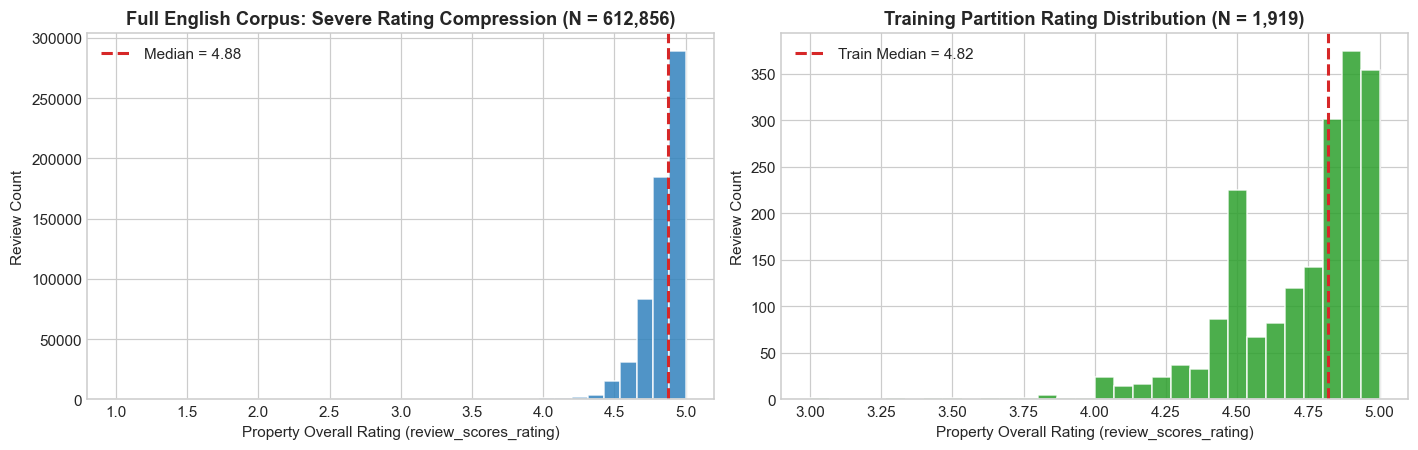

In [7]:
# Flag explicit dissatisfaction / complaint cues across the English corpus
dissat_lexicon_pattern = (
    r'\b(?:dirty|filthy|stain|stains|smell|smelled|odor|cockroach|roach|bedbug|mold|mould|'
    r'dusty|unclean|broken|freezing|unresponsive|rude|terrible|horrible|awful|disappointed|'
    r'disappointing|worst|refund|unacceptable|not clean|not working|never again|'
    r'would not recommend|do not stay|don\'t stay)\b'
)
df_en['dissatisfied_cue'] = df_en['comments'].str.contains(dissat_lexicon_pattern, case=False, regex=True)

# Construct reproducible stratified working sample of MAX_REVIEWS = 3,000
stratum_dissat_or_low = df_en.loc[(df_en['review_scores_rating'] < 4.55) | df_en['dissatisfied_cue']]
stratum_standard = df_en.loc[~df_en.index.isin(stratum_dissat_or_low.index)]

df = pd.concat([
    stratum_dissat_or_low.sample(n=1200, random_state=SEED),
    stratum_standard.sample(n=MAX_REVIEWS - 1200, random_state=SEED)
]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
df.index.name = 'row_id'

# Create rating / satisfaction stratification key for train / validation / test split
df['strata_key'] = (
    df['dissatisfied_cue'].astype(str) + '_' +
    pd.qcut(df['review_scores_rating'], q=3, labels=['Low', 'Mid', 'High'], duplicates='drop').astype(str)
)

# Listing-level split: every listing's reviews go to exactly one partition (target is listing-level).
# StratifiedGroupKFold with 5 folds -> one fold (~20%) is held out; strata stay balanced.
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_pos, test_pos = next(outer_split.split(df, df['strata_key'], groups=df['listing_id']))
dev, test = df.iloc[dev_pos].copy(), df.iloc[test_pos].copy()

inner_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_pos, valid_pos = next(inner_split.split(dev, dev['strata_key'], groups=dev['listing_id']))
train, valid = dev.iloc[train_pos].copy(), dev.iloc[valid_pos].copy()
test = test.copy()

assert set(train.index).isdisjoint(valid.index), 'Train and validation indices must be disjoint!'
assert set(dev.index).isdisjoint(test.index), 'Development and test indices must be disjoint!'
print('Partition sizes:', {'dev': len(dev), 'train': len(train), 'validation': len(valid), 'test': len(test)})

# Data reasoning checks used in Section 1.4
print(f"Full English corpus listing rating: median = {df_en['review_scores_rating'].median():.2f}, "
      f"mean = {df_en['review_scores_rating'].mean():.2f}, "
      f"reviews on listings rated < 4.50 = {100 * (df_en['review_scores_rating'] < 4.50).mean():.1f}%")
print(f"Complaint-cue rate: full English corpus = {100 * df_en['dissatisfied_cue'].mean():.1f}% | "
      f"working sample = {100 * df['dissatisfied_cue'].mean():.1f}%")

# Leakage check: the target is listing-level, so no listing may appear in two partitions
shared_dev_test = set(dev['listing_id']) & set(test['listing_id'])
shared_train_valid = set(train['listing_id']) & set(valid['listing_id'])
assert not shared_dev_test and not shared_train_valid, 'A listing appears in more than one partition!'
print(f"Listings per partition: train = {train['listing_id'].nunique()}, validation = {valid['listing_id'].nunique()}, "
      f"test = {test['listing_id'].nunique()} | listings shared across partitions = 0")
print('Review share per partition (%):', {name: round(100 * len(part) / len(df), 1)
      for name, part in [('train', train), ('validation', valid), ('test', test)]})

# Visualize full-corpus rating compression vs working sample rating distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df_en['review_scores_rating'], bins=35, color='#3182bd', edgecolor='white', alpha=0.85)
axes[0].axvline(df_en['review_scores_rating'].median(), color='#d62728', linestyle='--', lw=2,
                label=f'Median = {df_en["review_scores_rating"].median():.2f}')
axes[0].set_title(f'Full English Corpus: Severe Rating Compression (N = {len(df_en):,})', fontweight='bold')
axes[0].set_xlabel('Property Overall Rating (review_scores_rating)')
axes[0].set_ylabel('Review Count')
axes[0].legend()

axes[1].hist(train['review_scores_rating'], bins=30, color='#2ca02c', edgecolor='white', alpha=0.85)
axes[1].axvline(train['review_scores_rating'].median(), color='#d62728', linestyle='--', lw=2,
                label=f'Train Median = {train["review_scores_rating"].median():.2f}')
axes[1].set_title(f'Training Partition Rating Distribution (N = {len(train):,})', fontweight='bold')
axes[1].set_xlabel('Property Overall Rating (review_scores_rating)')
axes[1].set_ylabel('Review Count')
axes[1].legend()
plt.tight_layout()
plt.show()


## **2. Custom Text Preprocessing: Host Nicknames (Steps 4 & 7), Sentiment-Flipping Negations (Step 5), Stopwords (Step 6), and Lemmatization (Step 7)**

Following **Steps 4, 5, 6, and 7** of Team Seven's proposal and the methodology in `04_Quantifying_Texts`, we design a domain-aware text preprocessing pipeline tailored specifically to Airbnb reviews:

1. **Step 4 & Step 7 — Replacing `host_name` and Host Nicknames with `host_name_token`:**
   - Guests frequently thank or criticize their host by name (e.g., *"Alexandra was so welcoming"*, *"Alex never replied to our messages"*). If left untreated, common first names (*David*, *Michael*, *Sarah*, *Alex*, *Daniel*, *Matthew*) act as noisy high-frequency tokens that fragment topic models by host identity rather than semantic theme.
   - Furthermore, per **Step 7**, guests often use a shortened nickname when the host's listed name is formal (e.g., listing says `Alexandra` or `Alexander`, guest writes `Alex`; listing says `Matthew`, guest writes `Matt`; listing says `Michael`, guest writes `Mike`). Our dictionary maps 40+ common English formal/nickname pairs for each review's specific `host_name` and replaces every match with `host_name_token`, while recording `mentions_host_name` (0/1) and `host_mention_count` for our **Michelin Star host-interaction analysis**. Name variants that are also ordinary English words (e.g., `will`, `bill`, `sandy`, `joy`, `grace`) are excluded, so a review saying "we will return" is not counted as mentioning a host named William.
2. **Step 5 — Flagging Stop Words That Flip Sentiments with Valuable Tokens:**
   - Standard stopword lists (`nltk.corpus.stopwords` and `ENGLISH_STOP_WORDS`) strip negation words (`not`, `no`, `never`, `n't`). In Airbnb reviews, removing negations turns *"The apartment was **not** clean and the heater did **not** work"* into *"apartment clean heater work"* — completely inverting a 1-star complaint into positive words!
   - Conversely, guests also use **litotes (double-negative praise)** such as *"The stay did **not** disappoint"* or *"We would **not** hesitate to book again."*
   - To preserve sentiment flips in our Bag-of-Words, TF–IDF, and LDA representations, we intercept negation modifiers (`not`, `no`, `never`, `neither`, `hardly`, `barely`, `n't`) and bind them to the following lemmatized content word as a compound token (`not_clean`, `not_work`, `not_recommend` vs. `not_disappoint`, `not_hesitate`), while keeping the **raw, unstripped review text** intact for `TextBlob` polarity scoring.
3. **Step 6 & Step 7 — Stopword Removal and POS-Aware WordNet Lemmatization:**
   - We apply `WordNetLemmatizer` across verb and noun forms (so *"cleaned/cleaning"* $\rightarrow$ *"clean"*, *"stains/stained"* $\rightarrow$ *"stain"*, *"smelled/smells"* $\rightarrow$ *"smell"*, *"working/worked"* $\rightarrow$ *"work"*) and remove non-informative stopwords and domain-boilerplate words (`airbnb`, `toronto`, `stay`, `stayed`).


In [8]:
# Step 7: Bi-directional formal name <-> nickname lookup table for host_name normalization
NICKNAME_MAP = {
    'alexander': ['alex', 'sandy'], 'alexandra': ['alex', 'lexi'], 'michael': ['mike', 'mick'],
    'matthew': ['matt'], 'daniel': ['dan', 'danny'], 'david': ['dave'], 'christopher': ['chris'],
    'nicholas': ['nick'], 'elizabeth': ['liz', 'beth', 'eliza'], 'katherine': ['kate', 'kathy', 'katie'],
    'catherine': ['kate', 'cathy', 'katie'], 'robert': ['rob', 'bob', 'bobby'], 'william': ['will', 'bill', 'billy'],
    'thomas': ['tom', 'tommy'], 'jennifer': ['jen', 'jenny'], 'benjamin': ['ben'], 'samuel': ['sam'],
    'andrew': ['andy', 'drew'], 'stephanie': ['steph'], 'joshua': ['josh'], 'anthony': ['tony'],
    'joseph': ['joe', 'joey'], 'jonathan': ['jon'], 'rebecca': ['becky'], 'victoria': ['vicky', 'tori'],
    'richard': ['rick', 'dick'], 'charles': ['charlie', 'chuck'], 'patricia': ['pat', 'trish'],
    'steven': ['steve'], 'stephen': ['steve'], 'timothy': ['tim'], 'kenneth': ['ken', 'kenny'],
    'edward': ['ed', 'eddie'], 'ronald': ['ron'], 'jeffrey': ['jeff'], 'gregory': ['greg'],
    'deborah': ['deb', 'debbie'], 'susan': ['sue', 'suzie'], 'margaret': ['maggie', 'meg', 'peggy'],
    'jacqueline': ['jackie'], 'christina': ['chris', 'tina'], 'natalie': ['nat'], 'philip': ['phil']
}

# Step 5: Sentiment-flipping negation words excluded from naive stopword deletion
NEGATION_WORDS = {
    'not', 'no', 'never', 'neither', 'nor', 'hardly', 'barely',
    'wasnt', 'werent', 'isnt', 'arent', 'didnt', 'doesnt', 'dont',
    'couldnt', 'wouldnt', 'shouldnt', 'wont', 'cant', 'cannot'
}

# Step 6: Base English stopwords (minus negations) + Airbnb domain boilerplate words
base_stop_words = (set(stopwords.words('english')) | set(ENGLISH_STOP_WORDS)) - NEGATION_WORDS
domain_boilerplate = {
    'airbnb', 'toronto', 'stay', 'stayed', 'staying', 'place', 'also',
    'really', 'very', 'would', 'get', 'got', 'one', 'two', 'us'
}
ALL_STOP_WORDS = base_stop_words | domain_boilerplate

# Name variants that are also common English words are never treated as host mentions
AMBIGUOUS_NAME_WORDS = {
    'will', 'bill', 'pat', 'sue', 'rob', 'drew', 'sandy', 'chuck', 'dick', 'nat',
    'joy', 'grace', 'hope', 'faith', 'sunny', 'rose', 'summer', 'may', 'june',
    'star', 'king', 'love', 'happy', 'lucky', 'honey', 'sky', 'river', 'city'
}

lemmatizer = WordNetLemmatizer()

def lemmatize_token(word):
    # Apply verb lemmatization first (e.g. 'smelled'->'smell', 'working'->'work'), then noun lemmatization ('stains'->'stain')
    v_lemma = lemmatizer.lemmatize(word, pos='v')
    return lemmatizer.lemmatize(v_lemma, pos='n')

def extract_host_variants(host_name):
    if pd.isna(host_name):
        return set()
    raw_parts = re.findall(r'[a-z]+', str(host_name).lower())
    non_name_words = {'and', 'the', 'group', 'home', 'homes', 'suites', 'suite', 'residence', 'property', 'management', 'inc', 'host', 'team', 'toronto', 'stay'}
    variants = {w for w in raw_parts if len(w) >= 3 and w not in ALL_STOP_WORDS and w not in non_name_words}
    for w in list(variants):
        if w in NICKNAME_MAP:
            variants.update(NICKNAME_MAP[w])
        for formal_name, nicks in NICKNAME_MAP.items():
            if w in nicks:
                variants.add(formal_name)
                variants.update(nicks)
    return variants - AMBIGUOUS_NAME_WORDS

def preprocess_review_row(row):
    text = str(row['comments'])
    host_variants = extract_host_variants(row['host_name'])

    # Normalize curly apostrophes and expand "n't" to " not" so contractions trigger negation binding
    normalized = text.lower().replace('’', "'").replace("n't", " not")
    alpha_only = re.sub(r'[^a-z\s]', ' ', normalized)
    raw_tokens = word_tokenize(alpha_only, preserve_line=True)

    # Step 4 & Step 7: Replace host_name and nickname matches with generic 'host_name_token'
    host_replaced = []
    host_mentions = 0
    for tok in raw_tokens:
        if tok in host_variants:
            host_replaced.append('host_name_token')
            host_mentions += 1
        else:
            host_replaced.append(tok)

    # Step 5, 6, 7: Bind negation flips ('not_<lemma>') and lemmatize remaining content words
    processed_tokens = []
    neg_count = 0
    i = 0
    while i < len(host_replaced):
        tok = host_replaced[i]
        if tok in NEGATION_WORDS:
            neg_count += 1
            bound = False
            for j in range(i + 1, min(i + 4, len(host_replaced))):
                nxt = host_replaced[j]
                if nxt not in ALL_STOP_WORDS and nxt not in NEGATION_WORDS and nxt != 'host_name_token' and len(nxt) > 2:
                    lemma_nxt = lemmatize_token(nxt)
                    processed_tokens.append(f'not_{lemma_nxt}')
                    i = j + 1
                    bound = True
                    break
            if not bound:
                processed_tokens.append('not_token')
                i += 1
        elif tok == 'host_name_token':
            processed_tokens.append('host_name_token')
            i += 1
        elif tok not in ALL_STOP_WORDS and len(tok) > 2:
            lemma_tok = lemmatize_token(tok)
            if lemma_tok not in ALL_STOP_WORDS and len(lemma_tok) > 2:
                processed_tokens.append(lemma_tok)
            i += 1
        else:
            i += 1

    return pd.Series({
        'tokenized': word_tokenize(text.lower(), preserve_line=True),
        'processed': ' '.join(processed_tokens[:TOPIC_WORD_LIMIT]),
        'host_mention_count': host_mentions,
        'mentions_host_name': int(host_mentions > 0),
        'negation_count': neg_count
    })

# Demonstrate the pipeline on synthetic Airbnb examples (Host Nickname + Negation Flip vs Naive Cleaning)
demo_examples = pd.DataFrame([
    {'host_name': 'Alexandra', 'comments': "Alex's apartment was super clean and everything worked!"},
    {'host_name': 'Alexandra', 'comments': "Alex's apartment was NOT clean and the heater didn't work!"},
    {'host_name': 'Matthew & Sarah', 'comments': "Matt was responsive and the condo did not disappoint, would not hesitate to return!"}
])
demo_out = demo_examples.apply(preprocess_review_row, axis=1)
demo_comparison = pd.DataFrame({
    'Host_Name': demo_examples['host_name'],
    'Original_Review': demo_examples['comments'],
    'TextBlob_Polarity (Raw)': [round(TextBlob(t).sentiment.polarity, 4) for t in demo_examples['comments']],
    'Processed_Tokens (Host + Negation Preserved)': demo_out['processed']
})
display(demo_comparison)


,Host_Name,Original_Review,TextBlob_Polarity (Raw),Processed_Tokens (Host + Negation Preserved)
0,Alexandra,Alex's apartment was super clean and everything worked!,0.3958,host_name_token apartment super clean work
1,Alexandra,Alex's apartment was NOT clean and the heater didn't work!,-0.2292,host_name_token apartment not_clean heater not_work
2,Matthew & Sarah,"Matt was responsive and the condo did not disappoint, would not hesitate to return!",0.0000,host_name_token responsive condo not_disappoint not_hesitate return


In [9]:
# Apply custom preprocessing across train, valid, and test partitions (row-wise deterministic transformation)
t_prep = time.perf_counter()
for part_name, part_df in [('train', train), ('valid', valid), ('test', test)]:
    res = part_df.apply(preprocess_review_row, axis=1)
    for col in res.columns:
        part_df[col] = res[col]

# Also sync columns back to df and dev by index
for col in ['tokenized', 'processed', 'host_mention_count', 'mentions_host_name', 'negation_count']:
    df.loc[train.index, col] = train[col]
    df.loc[valid.index, col] = valid[col]
    df.loc[test.index, col] = test[col]
    dev.loc[train.index, col] = train[col]
    dev.loc[valid.index, col] = valid[col]

print(f'Processed {len(df):,} working reviews in {time.perf_counter() - t_prep:.2f}s')
print(f'Share of training reviews mentioning host by name/nickname: {100*train["mentions_host_name"].mean():.1f}%')
display(train[['listing_id', 'host_name', 'comments', 'processed', 'mentions_host_name', 'negation_count']].head(3))


Processed 3,000 working reviews in 1.43s
Share of training reviews mentioning host by name/nickname: 33.2%


,listing_id,host_name,comments,processed,mentions_host_name,negation_count
row_id,,,,,,
0,31490902,Nikola,"This is my first time using Airbnb, Nikola is such an amazing host. He provided everything you need during your stay...",time use host_name_token amaze host provide need recommendation make trip enjoyable,1,0
2,979067597811445456,Charith,Thank you so much for being a great host to communicating back to me in a timely matter,thank great host communicate timely matter,0,0
4,736058180870742630,Warren,Myself and 3 friends stayed for 2 nights for a girls weekend. We absolutely loved the location -- such a cute area a...,friend night girl weekend absolutely love location cute area host_name_token perfect smaller sleep night not_big dea...,1,1


### **2.1 Frequent Terms Before vs. After Filtering & Top Negation-Bound Tokens**

Following **Section 2 of `04_Quantifying_Texts`**, we compare the 20 most frequent tokens in our training corpus **before filtering** (which is dominated by punctuation, articles, and prepositions) versus **after filtering** (where domain-meaningful concepts such as `great`, `host_name_token`, `host`, `clean`, `location`, `nice`, `recommend`, `comfortable`, and `walk` emerge clearly). We also inspect the top **negation-bound tokens (`not_<lemma>`)** captured by **Step 5**.


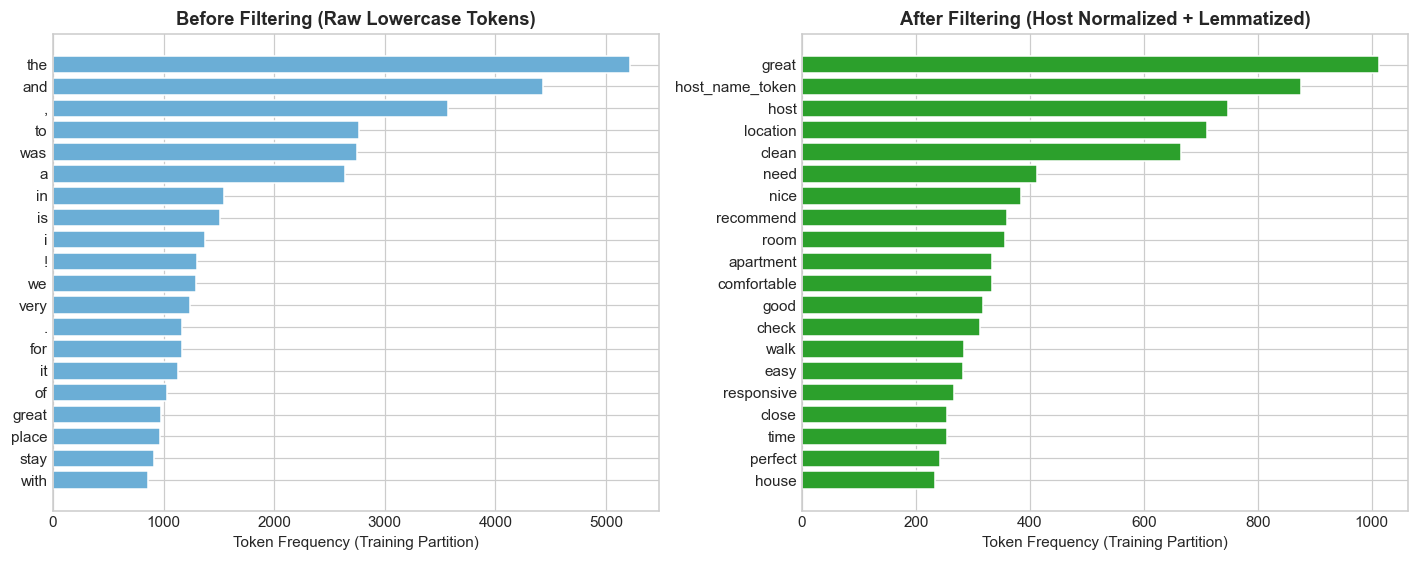

Unique raw tokens (train): 7,358 | Unique filtered tokens (train): 4,113

Step 5 Validation — Top 12 Negation-Bound Tokens in Training Reviews:


,Negation_Bound_Token,Train_Count,Semantic_Role
0,not_work,33,Dissatisfaction / Operational Complaint Flip
1,not_clean,30,Dissatisfaction / Operational Complaint Flip
2,not_recommend,28,Dissatisfaction / Operational Complaint Flip
3,not_disappoint,20,Litotes / Double-Negative Praise
4,not_problem,19,Litotes / Double-Negative Praise
5,not_use,14,Dissatisfaction / Operational Complaint Flip
6,not_beat,14,Litotes / Double-Negative Praise
7,not_issue,14,Litotes / Double-Negative Praise
8,not_want,13,Dissatisfaction / Operational Complaint Flip
9,not_meet,12,Dissatisfaction / Operational Complaint Flip


In [10]:
before_counts = Counter(chain.from_iterable(train['tokenized']))
after_counts = Counter(chain.from_iterable(train['processed'].str.split()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, counts, title, color in zip(
    axes,
    [before_counts, after_counts],
    ['Before Filtering (Raw Lowercase Tokens)', 'After Filtering (Host Normalized + Lemmatized)'],
    ['#6baed6', '#2ca02c']
):
    top20 = counts.most_common(20)
    words, freqs = zip(*reversed(top20))
    ax.barh(words, freqs, color=color, edgecolor='white')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Token Frequency (Training Partition)')
plt.tight_layout()
plt.show()

print(f'Unique raw tokens (train): {len(before_counts):,} | Unique filtered tokens (train): {len(after_counts):,}')

# Inspect Top 12 Negation-Bound Tokens (Step 5) separating True Complaints vs Litotes Praise
neg_tokens = [w for w in chain.from_iterable(train['processed'].str.split()) if w.startswith('not_') and w != 'not_token']
neg_counts = Counter(neg_tokens).most_common(12)
neg_df = pd.DataFrame(neg_counts, columns=['Negation_Bound_Token', 'Train_Count'])
neg_df['Semantic_Role'] = neg_df['Negation_Bound_Token'].map(
    lambda x: 'Litotes / Double-Negative Praise' if x in {'not_disappoint', 'not_hesitate', 'not_issue', 'not_problem', 'not_far', 'not_bad', 'not_beat'}
    else 'Dissatisfaction / Operational Complaint Flip'
)
print('\nStep 5 Validation — Top 12 Negation-Bound Tokens in Training Reviews:')
display(neg_df)


## **3. Bag-of-Words (Step 3), Explicit TF, IDF, and TF–IDF Representation, and Truncated SVD (Step 8)**

### **3.1 Step 3 & Step 8: Explicit Calculation of Term Frequency (TF), Inverse Document Frequency (IDF), and TF–IDF**

Per **Step 3** and **Step 8** of our analytical plan (*"3. Bag-of-words the reviews ... 8. Calculate tf, idf, then tf-idf"*), we construct both the **Bag-of-Words count matrix** (`CountVectorizer`) and the **TF–IDF matrix** (`TfidfVectorizer`) fitted strictly on the **training partition** (`min_df=3, max_df=0.90, max_features=2000`):

- **Term Frequency ($\text{TF}_{d,t}$):** Measures how often term $t$ appears in review $d$.
- **Inverse Document Frequency ($\text{IDF}_t = \ln\frac{1 + N}{1 + \text{DF}_t} + 1$):** Downweights ubiquitous words (`great`, `clean`, `location`) that appear in thousands of reviews and boosts rare, diagnostic words (`stain`, `smell`, `not_work`, `not_clean`, `cockroach`, `refund`).
- **TF–IDF ($\text{TF–IDF}_{d,t} = \text{TF}_{d,t} \times \text{IDF}_t$, $\ell_2$-normalized):** Highlights terms that are locally prominent within a specific review and globally distinctive across the corpus.


In [11]:
# Step 3 & Step 8: Fit Bag-of-Words (TF counts) and TF-IDF strictly on training reviews
bow_vectorizer = CountVectorizer(min_df=3, max_df=0.90, max_features=MAX_TERMS, token_pattern=r'[a-z_]+')
X_bow_train = bow_vectorizer.fit_transform(train['processed'])

tfidf_vectorizer = TfidfVectorizer(min_df=3, max_df=0.90, max_features=MAX_TERMS, token_pattern=r'[a-z_]+')
X_tfidf_train = tfidf_vectorizer.fit_transform(train['processed'])
X_tfidf_valid = tfidf_vectorizer.transform(valid['processed'])
X_tfidf_test = tfidf_vectorizer.transform(test['processed'])

terms = tfidf_vectorizer.get_feature_names_out()
assert X_tfidf_train.shape[0] == len(train)
print(f'Training Document-Term Matrix Shape : {X_tfidf_train.shape}')
print(f'Retained Vocabulary Size            : {len(terms):,}')
print(f'Matrix Sparsity (Zero Entries)      : {100 * (1 - X_tfidf_train.nnz / np.prod(X_tfidf_train.shape)):.2f}%')

# Build an explicit Step 8 breakdown table comparing TF, DF, IDF, and TF-IDF across key domain & complaint terms
term_to_idx = {t: i for i, t in enumerate(terms)}
total_tf = np.asarray(X_bow_train.sum(axis=0)).ravel()
doc_freq = np.asarray((X_bow_train > 0).sum(axis=0)).ravel()
idf_vals = tfidf_vectorizer.idf_
mean_tfidf = np.asarray(X_tfidf_train.mean(axis=0)).ravel()
mean_nonzero_tfidf = np.asarray(X_tfidf_train.sum(axis=0)).ravel() / np.maximum(doc_freq, 1)

focus_terms = [
    'great', 'host_name_token', 'clean', 'location', 'comfortable', 'walk',
    'dirty', 'smell', 'stain', 'not_work', 'not_clean', 'not_recommend', 'refund', 'noisy'
]
step8_rows = []
for t in focus_terms:
    if t in term_to_idx:
        idx = term_to_idx[t]
        step8_rows.append({
            'Term': t,
            'Category': 'Praise / Core Attribute' if t in {'great', 'host_name_token', 'clean', 'location', 'comfortable', 'walk'} else 'Dissatisfaction / Complaint',
            'Corpus_TF (Total Count)': int(total_tf[idx]),
            'Doc_Freq (DF)': int(doc_freq[idx]),
            'Doc_Share_%': round(100 * doc_freq[idx] / len(train), 2),
            'IDF_Weight': round(float(idf_vals[idx]), 3),
            'Mean_TFIDF (All Docs)': round(float(mean_tfidf[idx]), 4),
            'Mean_TFIDF (When Present)': round(float(mean_nonzero_tfidf[idx]), 3)
        })
step8_df = pd.DataFrame(step8_rows)
print('\nStep 8 Explicit Breakdown: TF, DF, IDF, and TF-IDF for Core vs. Complaint Vocabulary:')
display(step8_df)


Training Document-Term Matrix Shape : (1919, 1497)
Retained Vocabulary Size            : 1,497
Matrix Sparsity (Zero Entries)      : 98.83%

Step 8 Explicit Breakdown: TF, DF, IDF, and TF-IDF for Core vs. Complaint Vocabulary:


,Term,Category,Corpus_TF (Total Count),Doc_Freq (DF),Doc_Share_%,IDF_Weight,Mean_TFIDF (All Docs),Mean_TFIDF (When Present)
0,great,Praise / Core Attribute,1013,802,41.79,1.872,0.0728,0.174
1,host_name_token,Praise / Core Attribute,875,637,33.19,2.102,0.0534,0.161
2,clean,Praise / Core Attribute,665,615,32.05,2.137,0.0461,0.144
3,location,Praise / Core Attribute,711,667,34.76,2.056,0.0507,0.146
4,comfortable,Praise / Core Attribute,333,302,15.74,2.846,0.0283,0.180
5,walk,Praise / Core Attribute,285,245,12.77,3.055,0.0196,0.153
6,dirty,Dissatisfaction / Complaint,65,50,2.61,4.628,0.0051,0.194
7,smell,Dissatisfaction / Complaint,82,74,3.86,4.243,0.0068,0.175
8,stain,Dissatisfaction / Complaint,35,31,1.62,5.094,0.0028,0.174
9,not_work,Dissatisfaction / Complaint,33,30,1.56,5.126,0.0030,0.193


**Interpretation of the TF $\rightarrow$ IDF $\rightarrow$ TF–IDF Progression:**
- Common praise words are present in a large share of training reviews: `great` (DF = 41.8%, IDF = 1.872), `location` (34.8%, IDF = 2.056), `host_name_token` (33.2%, IDF = 2.102), and `clean` (32.0%, IDF = 2.137). Because they appear so often, they have the highest average TF–IDF across all reviews.
- Complaint tokens are much rarer: `smell` (3.9% of reviews, IDF = 4.243), `dirty` (2.6%, IDF = 4.628), `stain` (1.6%, IDF = 5.094), `not_work` (1.6%, IDF = 5.126), and `not_clean` (1.5%, IDF = 5.193). Their IDF weights are roughly 2.3–2.8 times that of `great`.
- **When a complaint term is present**, its TF–IDF weight is usually similar to or higher than that of praise terms (mostly 0.17–0.23 vs. 0.14–0.18), even though complaints appear in far fewer reviews. TF–IDF therefore keeps rare complaint words visible inside the reviews where they occur, instead of letting common praise words dominate.
- **Caveat:** several of these complaint words (`dirty`, `smell`, `stain`, `refund`) are also in the complaint lexicon used to flag dissatisfied reviews, so their association with dissatisfaction is partly built in.

### **3.2 Inspect One Dissatisfied Review's High-Weight TF–IDF Terms**
Following **Section 3 of `04_Quantifying_Texts`**, we inspect a concrete training review alongside its 8 largest TF–IDF weights and a 5-review dense matrix slice. (The review selected here was flagged only because it mentions "below freezing" weather, which shows that the keyword-based complaint flag can misfire.)

In [12]:
# Select a representative dissatisfied review with at least 6 retained TF-IDF terms
term_counts_row = X_tfidf_train.getnnz(axis=1)
cand_rows = np.flatnonzero((term_counts_row >= 6) & train['dissatisfied_cue'].to_numpy())
example_pos = int(cand_rows[0] if len(cand_rows) else np.argmax(term_counts_row))
example_idx = train.index[example_pos]

print(f'Example Training Review (row_id={example_idx}, listing_id={train.loc[example_idx, "listing_id"]}, listing rating={train.loc[example_idx, "review_scores_rating"]}):')
print(train.loc[example_idx, 'comments'])

row_vec = X_tfidf_train.getrow(example_pos)
order = np.argsort(row_vec.data)[::-1][:8]
example_terms = terms[row_vec.indices[order]]
display(pd.DataFrame({'Term': example_terms, 'TF_IDF_Weight': row_vec.data[order]}).round(3))

# Dense conversion limited to a 5-by-8 illustration (following Notebook 04)
small_slice = X_tfidf_train[:5, row_vec.indices[order]].toarray()
display(pd.DataFrame(
    small_slice,
    index=[f'Train Row {i}' for i in range(5)],
    columns=example_terms
).round(3))


Example Training Review (row_id=19, listing_id=1460222460503280883, listing rating=4.98):
We came to Toronto for a concert at the Scotiabank Arena and Stephen's place couldn't have been more convenient, especially given that it was below freezing outside! We could walk to anything we needed within 5 minutes. The space itself is simple and functional, and met all our needs for the two nights we were there.


,Term,TF_IDF_Weight
0,arena,0.314
1,scotiabank,0.314
2,functional,0.314
3,freeze,0.303
4,simple,0.270
5,concert,0.265
6,need,0.261
7,meet,0.253


,arena,scotiabank,functional,freeze,simple,concert,need,meet
Train Row 0,0.0,0.0,0.0,0.0,0.0,0.0,0.209,0.0
Train Row 1,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0
Train Row 2,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0
Train Row 3,0.0,0.0,0.0,0.0,0.0,0.0,0.117,0.0
Train Row 4,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0


### **3.3 Truncated SVD: Compact Continuous Features and Interpretation**

Following **Section 4 of `04_Quantifying_Texts`**, we apply `TruncatedSVD(n_components=10, random_state=SEED)` to compress the sparse 1,497-term TF–IDF matrix into 10 continuous latent components. Each component is a linear combination of vocabulary terms. Remember that SVD component signs are arbitrary, so a negative loading indicates an opposing lexical contrast rather than negative sentiment. The 10 components explain only about 11% of the TF–IDF variance, so we use them as a compact predictor set in Section 7 rather than as interpretable themes.


1497 TF-IDF term columns compressed into 10 SVD components in 0.03s.
Cumulative explained variance (10 components): 10.8%


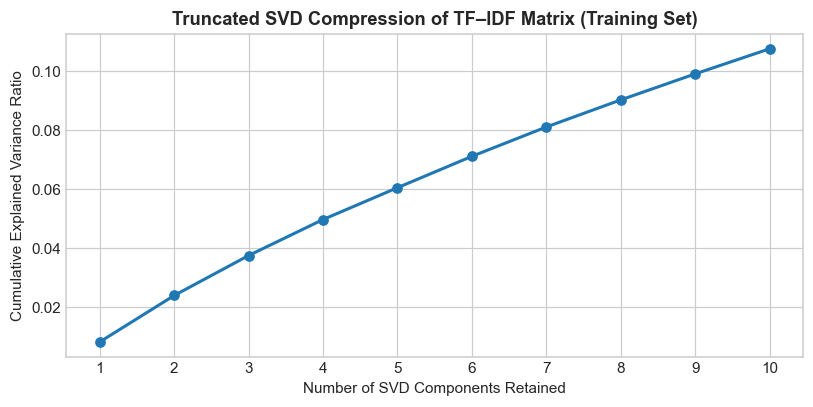

,Component,Explained_Var_%,Largest Positive Loadings,Most Negative Loadings
0,SVD_1,0.82,"great, host_name_token, location, host, clean, recommend",(none)
1,SVD_2,1.57,"great, location, view, definitely, awesome, communication","nice, host_name_token, room, home, good, like"
2,SVD_3,1.35,"nice, good, clean, location, room, quiet","amaze, recommend, host, host_name_token, highly, responsive"
3,SVD_4,1.22,"nice, recommend, highly, host, clean, good","host_name_token, perfect, thank, walk, need, check"


In [13]:
t_svd = time.perf_counter()
svd = TruncatedSVD(n_components=MAX_COMPONENTS, random_state=SEED)
X_svd_train = svd.fit_transform(X_tfidf_train)
X_svd_valid = svd.transform(X_tfidf_valid)
X_svd_test = svd.transform(X_tfidf_test)

svd_cols = [f'SVD_{i+1}' for i in range(MAX_COMPONENTS)]
svd_train_df = pd.DataFrame(X_svd_train, index=train.index, columns=svd_cols)
svd_valid_df = pd.DataFrame(X_svd_valid, index=valid.index, columns=svd_cols)
svd_test_df = pd.DataFrame(X_svd_test, index=test.index, columns=svd_cols)

cumulative_var = np.cumsum(svd.explained_variance_ratio_)
print(f'{X_tfidf_train.shape[1]} TF-IDF term columns compressed into {MAX_COMPONENTS} SVD components in {time.perf_counter()-t_svd:.2f}s.')
print(f'Cumulative explained variance (10 components): {cumulative_var[-1]:.1%}')

plt.figure(figsize=(7.5, 3.8))
plt.plot(np.arange(1, MAX_COMPONENTS + 1), cumulative_var, marker='o', color='#1f77b4', lw=2)
plt.xticks(np.arange(1, MAX_COMPONENTS + 1))
plt.xlabel('Number of SVD Components Retained')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('Truncated SVD Compression of TF–IDF Matrix (Training Set)', fontweight='bold')
plt.tight_layout()
plt.show()

# Inspect largest positive and most negative term loadings for the first 4 SVD components
loading_rows = []
for i, weights in enumerate(svd.components_[:4]):
    pos_idx = np.flatnonzero(weights > 0)
    neg_idx = np.flatnonzero(weights < 0)
    high_terms = pos_idx[np.argsort(weights[pos_idx])[-6:][::-1]]
    low_terms = neg_idx[np.argsort(weights[neg_idx])[:6]]
    loading_rows.append({
        'Component': svd_cols[i],
        'Explained_Var_%': round(100 * svd.explained_variance_ratio_[i], 2),
        'Largest Positive Loadings': ', '.join(terms[high_terms]),
        'Most Negative Loadings': ', '.join(terms[low_terms]) if len(low_terms) else '(none)'
    })
display(pd.DataFrame(loading_rows))


## **4. Sentiment Polarity and Normalized NRC Emotion Features**

Following **`05_Text_Features_and_Rating_Prediction`** and **Parts II–III of `Assignment #2`**:
1. **`TextBlob_Sentiment` (Polarity on Original Text):** Scored on the **original, unstripped review text** (`comments`) so that negation modifiers (`not`, `never`, `n't`), intensifiers (`very`, `extremely`), and exclamation marks remain intact. Polarity ranges from $-1.0$ (most negative) to $+1.0$ (most positive).
2. **`NRCLex` Normalized Emotion Rates (`_per100`) and `Review_Length`:** For each of the 8 core NRC emotions (`anger`, `fear`, `anticipation`, `trust`, `surprise`, `sadness`, `joy`, `disgust`), we compute:
   $$\text{Emotion Rate per 100 Words} = \frac{100 \times \text{Matched Emotion Token Count}}{\max(\text{Total Lexical Token Count}, 1)}$$
   Crucially, the denominator uses **all lexical tokens before topic stopword removal** so that emotion density is measured relative to total spoken verbosity, while `Review_Length` is retained as a separate predictor because dissatisfied guests recounting multi-point grievances write significantly longer reviews than satisfied guests leaving brief praise.


In [14]:
def word_tokens(text):
    # Lightweight lexical matching on original review text (consistent with Notebook 05 / Assignment #2)
    return re.findall(r"[a-z]+(?:'[a-z]+)?", str(text).lower().replace('’', "'"))

def sentiment_features(frame):
    # Score original review text, preserving negations, punctuation, and intensifiers
    return pd.DataFrame({
        'TextBlob_Sentiment': frame['comments'].map(lambda text: TextBlob(str(text)).sentiment.polarity)
    }, index=frame.index)

emotion_reader = NRCLex()  # Load bundled NRC lexicon once outside the row loop

def emotion_features(frame):
    records = []
    for text in frame['comments']:
        tokens = word_tokens(text)
        emotion_reader.load_token_list(tokens)
        counts = dict(emotion_reader.raw_emotion_scores)
        record = {'Review_Length': len(tokens)}
        record.update({
            f'{e}_per100': 100.0 * counts.get(e, 0) / max(len(tokens), 1)
            for e in EMOTIONS
        })
        records.append(record)
    return pd.DataFrame(records, index=frame.index)

def base_features(frame):
    return sentiment_features(frame).join(emotion_features(frame))

t_feat = time.perf_counter()
base_train = base_features(train)
base_valid = base_features(valid)
base_test = base_features(test)

# Attach sentiment and emotion columns to train/valid/test frames for cross-analysis
for part_df, b_df in [(train, base_train), (valid, base_valid), (test, base_test)]:
    for col in b_df.columns:
        part_df[col] = b_df[col]

# Define unified Dissatisfaction Indicator: either negative/near-zero polarity (< 0.05) or explicit complaint lexicon match
for part_df in (train, valid, test):
    part_df['is_dissatisfied'] = (part_df['TextBlob_Sentiment'] < 0.05) | part_df['dissatisfied_cue']

print(f'Extracted TextBlob sentiment and 8 NRC emotion rates in {time.perf_counter() - t_feat:.2f}s')
display(base_train.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))


Extracted TextBlob sentiment and 8 NRC emotion rates in 0.49s


,count,mean,std,min,50%,max
TextBlob_Sentiment,1919.0,0.382,0.233,-1.0,0.382,1.000
Review_Length,1919.0,50.052,53.612,2.0,33.000,805.000
anger_per100,1919.0,0.409,1.272,0.0,0.000,14.286
fear_per100,1919.0,0.338,1.039,0.0,0.000,13.333
anticipation_per100,1919.0,3.468,4.555,0.0,2.339,50.000
trust_per100,1919.0,6.219,6.837,0.0,4.545,60.000
surprise_per100,1919.0,1.619,3.500,0.0,0.000,50.000
sadness_per100,1919.0,1.023,2.457,0.0,0.000,28.571
joy_per100,1919.0,4.931,6.047,0.0,3.279,50.000
disgust_per100,1919.0,0.337,1.169,0.0,0.000,17.391


### **4.1 Empirical Comparison: Sentiment, Verbosity, and Emotion Rates in Satisfied vs. Dissatisfied Reviews**

Below we compare `TextBlob_Sentiment`, `Review_Length`, and the 8 NRC emotion rates across **Satisfied** vs. **Dissatisfied** training reviews, and test how distinctive TF–IDF vocabulary separates the two groups.

**Measurement caveat:** `is_dissatisfied` is defined as `TextBlob_Sentiment < 0.05` **or** a complaint-lexicon match. Differences in polarity, negation counts, and complaint words between the two groups are therefore partly built into the definition. Review length, emotion rates, and topic mixtures are the more informative comparisons.


,Satisfied_Reviews (Mean),Dissatisfied_Reviews (Mean),Relative_Ratio (Dissat / Sat)
TextBlob_Sentiment,0.443,0.095,0.214
Review_Length,39.666,99.699,2.513
negation_count,0.270,2.012,7.443
mentions_host_name,0.341,0.292,0.857
anger_per100,0.176,1.525,8.668
fear_per100,0.186,1.063,5.718
anticipation_per100,3.756,2.095,0.558
trust_per100,6.825,3.322,0.487
surprise_per100,1.757,0.960,0.546
sadness_per100,0.877,1.722,1.964


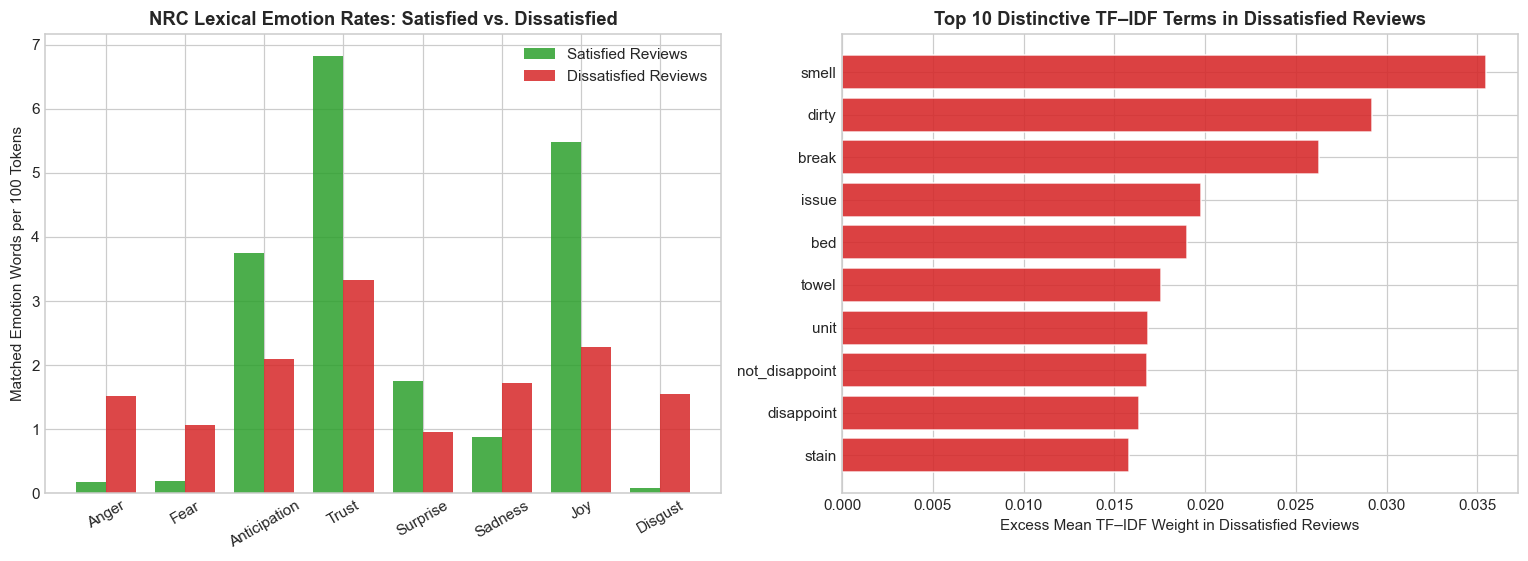

In [15]:
# Compare emotion rates, review length, and sentiment across Satisfied vs Dissatisfied reviews in train
emotion_summary = train.groupby('is_dissatisfied')[
    ['TextBlob_Sentiment', 'Review_Length', 'negation_count', 'mentions_host_name'] + EMOTION_COLS
].mean().T
emotion_summary.columns = ['Satisfied_Reviews (Mean)', 'Dissatisfied_Reviews (Mean)']
emotion_summary['Relative_Ratio (Dissat / Sat)'] = (
    emotion_summary['Dissatisfied_Reviews (Mean)'] / emotion_summary['Satisfied_Reviews (Mean)'].replace(0, np.nan)
)
display(emotion_summary.round(3))

# Plot NRC Emotion Rates & Distinctive TF-IDF Terms for Dissatisfied vs Satisfied Reviews
dissat_mask = train['is_dissatisfied'].to_numpy()
mean_tfidf_dissat = np.asarray(X_tfidf_train[dissat_mask].mean(axis=0)).ravel()
mean_tfidf_sat = np.asarray(X_tfidf_train[~dissat_mask].mean(axis=0)).ravel()
tfidf_diff = mean_tfidf_dissat - mean_tfidf_sat

top_dissat_idx = np.argsort(tfidf_diff)[-10:]
top_sat_idx = np.argsort(tfidf_diff)[:10][::-1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left panel: 8 NRC Emotion Rates (Satisfied vs Dissatisfied)
x_pos = np.arange(len(EMOTIONS))
width = 0.38
sat_emo_means = [train.loc[~train['is_dissatisfied'], f'{e}_per100'].mean() for e in EMOTIONS]
dis_emo_means = [train.loc[train['is_dissatisfied'], f'{e}_per100'].mean() for e in EMOTIONS]

axes[0].bar(x_pos - width/2, sat_emo_means, width, label='Satisfied Reviews', color='#2ca02c', alpha=0.85)
axes[0].bar(x_pos + width/2, dis_emo_means, width, label='Dissatisfied Reviews', color='#d62728', alpha=0.85)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels([e.capitalize() for e in EMOTIONS], rotation=30)
axes[0].set_ylabel('Matched Emotion Words per 100 Tokens')
axes[0].set_title('NRC Lexical Emotion Rates: Satisfied vs. Dissatisfied', fontweight='bold')
axes[0].legend()

# Right panel: Top 10 Distinctive TF-IDF Terms in Dissatisfied Reviews
axes[1].barh(terms[top_dissat_idx], tfidf_diff[top_dissat_idx], color='#d62728', edgecolor='white', alpha=0.88)
axes[1].set_xlabel('Excess Mean TF–IDF Weight in Dissatisfied Reviews')
axes[1].set_title('Top 10 Distinctive TF–IDF Terms in Dissatisfied Reviews', fontweight='bold')

plt.tight_layout()
plt.show()


**Interpretation of the Satisfied vs. Dissatisfied Comparison:**
- Dissatisfied reviews are about 2.5 times longer (99.7 vs. 39.7 words), consistent with guests describing several problems in detail.
- Their emotion profile shifts toward negative emotions: disgust (1.55 vs. 0.08 per 100 words), anger (1.53 vs. 0.18), fear (1.06 vs. 0.19), and sadness (1.72 vs. 0.88) are higher, while joy (2.28 vs. 5.49) and trust (3.32 vs. 6.83) are lower.
- Dissatisfied reviews mention the host by name slightly less often (29.2% vs. 34.1%).
- Polarity (0.10 vs. 0.44) and negation counts (2.01 vs. 0.27) also differ, but these are partly built into the dissatisfaction definition (see caveat above).

## **5. LDA Topic Modeling (Step 9) and Cross-Analysis with TF–IDF & Dissatisfaction (Step 10)**

### **5.1 Step 9: Latent Dirichlet Allocation (LDA) on Word Counts & UMass Coherence Selection**

Following **`05_Text_Features_and_Rating_Prediction`** and **Part IV of `Assignment #2`**, we fit Latent Dirichlet Allocation (`LatentDirichletAllocation`) on **word counts (`CountVectorizer`)** rather than TF–IDF, because LDA is a generative probabilistic model of discrete word occurrences.

To prevent ubiquitous generic praise words (`great`, `good`, `nice`, `clean`, `location`, `host`, `place`, `apartment`, `room`, `home`) from causing every topic to look identical, we filter out generic ubiquitous terms (`max_df=0.30` and domain-generic list) while retaining `host_name_token`, specific amenities, neighborhood/transit words, and all negation-bound tokens (`not_*`). We evaluate $K \in \{2, 3, 4\}$ on `topic_fit` (sampled strictly from `train`) using **UMass Coherence** and human interpretability.


LDA Count Matrix Shapes -> fit: (1500, 863) | train: (1919, 863) | valid: (480, 863)
K=2 fitted in 0.75s | UMass Coherence = -2.0428
K=3 fitted in 0.76s | UMass Coherence = -1.8643
K=4 fitted in 0.71s | UMass Coherence = -1.9921


,K,UMass,Seconds
0,2,-2.0428,0.7512
1,3,-1.8643,0.7614
2,4,-1.9921,0.7138


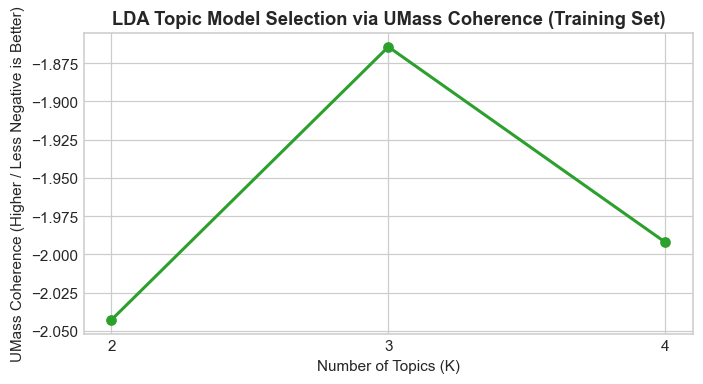


Top 10 Words per Topic for K=2:


,Topic_1,Topic_2
0,comfortable,check
1,perfect,beautiful
2,easy,space
3,park,love
4,walk,night
5,responsive,amaze
6,helpful,bed
7,close,unit
8,check,come
9,downtown,bathroom



Top 10 Words per Topic for K=3:


,Topic_1,Topic_2,Topic_3
0,comfortable,check,bed
1,perfect,beautiful,night
2,helpful,amaze,like
3,walk,close,unit
4,park,easy,issue
5,easy,space,shower
6,responsive,love,floor
7,check,responsive,bathroom
8,downtown,lot,day
9,friendly,lovely,leave



Top 10 Words per Topic for K=4:


,Topic_1,Topic_2,Topic_3,Topic_4
0,unit,easy,night,comfortable
1,perfect,check,bed,highly
2,park,beautiful,door,friendly
3,check,responsive,issue,enjoy
4,view,close,floor,helpful
5,walk,space,shower,quiet
6,build,amaze,station,perfect
7,bed,walk,like,love
8,like,communication,subway,wonderful
9,overall,restaurant,leave,super


In [16]:
LDA_GENERIC_STOPS = {
    'great', 'good', 'nice', 'well', 'definitely', 'recommend', 'everything',
    'need', 'time', 'make', 'made', 'even', 'back', 'much', 'little', 'bit',
    'not_token', 'clean', 'location', 'host', 'apartment', 'room', 'home', 'house', 'condo'
}

def clean_for_lda(processed_str):
    return ' '.join(w for w in str(processed_str).split() if w not in LDA_GENERIC_STOPS)

topic_fit = train.sample(n=min(TOPIC_FIT_LIMIT, len(train)), random_state=SEED)
lda_vectorizer = CountVectorizer(
    preprocessor=clean_for_lda,
    max_features=1500, min_df=5, max_df=0.30,
    tokenizer=str.split, token_pattern=None, lowercase=False
)

counts_fit = lda_vectorizer.fit_transform(topic_fit['processed'])
counts_train = lda_vectorizer.transform(train['processed'])
counts_valid = lda_vectorizer.transform(valid['processed'])
counts_test = lda_vectorizer.transform(test['processed'])

print('LDA Count Matrix Shapes -> fit:', counts_fit.shape, '| train:', counts_train.shape, '| valid:', counts_valid.shape)

topic_models, topic_rows = {}, []
for k in TOPIC_COUNTS:
    started = time.perf_counter()
    lda_candidate = new_lda(k).fit(counts_fit)
    topic_models[k] = lda_candidate
    topic_rows.append({
        'K': k,
        'UMass': umass_coherence(lda_candidate, counts_fit),
        'Seconds': time.perf_counter() - started
    })
    print(f'K={k} fitted in {topic_rows[-1]["Seconds"]:.2f}s | UMass Coherence = {topic_rows[-1]["UMass"]:.4f}')

topic_scores = pd.DataFrame(topic_rows)
display(topic_scores.round(4))

plt.figure(figsize=(6.5, 3.6))
plt.plot(topic_scores['K'], topic_scores['UMass'], marker='o', color='#2ca02c', lw=2)
plt.xticks(TOPIC_COUNTS)
plt.xlabel('Number of Topics (K)')
plt.ylabel('UMass Coherence (Higher / Less Negative is Better)')
plt.title('LDA Topic Model Selection via UMass Coherence (Training Set)', fontweight='bold')
plt.tight_layout()
plt.show()

for k, model_k in topic_models.items():
    print(f'\nTop 10 Words per Topic for K={k}:')
    display(pd.DataFrame(top_words(model_k, lda_vectorizer, n=10)))


### **5.2 Selecting $K = 3$, Validating Topic Mixtures on Representative Reviews, and Naming Themes**

**Coherence:** $K = 3$ has the highest (least negative) UMass coherence (−1.864), ahead of $K = 4$ (−1.992) and $K = 2$ (−2.043). The top words agree with this choice:
- $K = 2$ puts emotional praise words (`beautiful`, `love`, `amaze`) in the same topic as problem words (`bed`, `unit`, `bathroom`, `night`), so it cannot isolate the dissatisfaction theme.
- $K = 4$ spreads location words across topics (`walk` in two topics; `station` and `subway` inside the problem topic), making the themes harder to name.
- $K = 3$ separates one problem theme from two positive themes, so we choose **$K = 3$** (frozen before any test evaluation):
  - **`Topic_1` — *Practical Stay Quality (Comfort, Location & Helpfulness)*:** `comfortable`, `perfect`, `helpful`, `walk`, `park`, `easy`, `responsive`, `check`, `downtown`, `friendly`.
  - **`Topic_2` — *Enthusiastic Praise & Host Appreciation*:** `check`, `beautiful`, `amaze`, `close`, `easy`, `space`, `love`, `responsive`, `lot`, `lovely`.
  - **`Topic_3` — *Unit Operations & Problems*:** `bed`, `night`, `like`, `unit`, `issue`, `shower`, `floor`, `bathroom`, `day`, `leave`.
- **Overlap:** Topics 1 and 2 share several words (`easy`, `responsive`, `check`); both are positive, and the difference is mainly *tone* — practical descriptions of the stay vs. emotional praise and thanks to the host.

LDA numbers topics arbitrarily, so the code below assigns each label from the topic's word weights (anchor words such as `bathroom`/`bed`/`issue` for problems and `beautiful`/`amaze`/`love` for praise) instead of hard-coding the order. We then extract the $K = 3$ topic mixtures (`topic_train`, `topic_valid`, `topic_test`), verify that every review's topic weights sum to $1.0$, and inspect the two highest-weight training reviews for each topic to validate these labels against actual guest writing.

In [17]:
# Select K = 3 based on thematic interpretability and coherence stability (frozen before test evaluation)
chosen_k = 3
lda = topic_models[chosen_k]
topic_cols = [f'Topic_{i+1}' for i in range(chosen_k)]
# LDA numbers topics arbitrarily, so assign each label from the topic's word weights
lda_terms = list(lda_vectorizer.get_feature_names_out())
topic_word_share = lda.components_ / lda.components_.sum(axis=1, keepdims=True)

def anchor_score(words):
    idx = [lda_terms.index(w) for w in words if w in lda_terms]
    return topic_word_share[:, idx].sum(axis=1)

ops_k = int(np.argmax(anchor_score(['bathroom', 'bed', 'issue', 'floor', 'unit', 'shower'])))
praise_scores = anchor_score(['beautiful', 'amaze', 'love', 'lovely', 'wonderful'])
praise_scores[ops_k] = -np.inf
praise_k = int(np.argmax(praise_scores))
practical_k = ({0, 1, 2} - {ops_k, praise_k}).pop()
TOPIC_LABELS = {
    f'Topic_{practical_k + 1}': f'Topic {practical_k + 1}: Practical Stay Quality',
    f'Topic_{praise_k + 1}': f'Topic {praise_k + 1}: Enthusiastic Praise & Host Appreciation',
    f'Topic_{ops_k + 1}': f'Topic {ops_k + 1}: Unit Operations & Problems'
}
print('Topic labels assigned from top words:', TOPIC_LABELS)

topic_train = pd.DataFrame(lda.transform(counts_train), columns=topic_cols, index=train.index)
topic_valid = pd.DataFrame(lda.transform(counts_valid), columns=topic_cols, index=valid.index)
topic_test = pd.DataFrame(lda.transform(counts_test), columns=topic_cols, index=test.index)

assert np.allclose(topic_train.sum(axis=1), 1.0)
assert np.allclose(topic_valid.sum(axis=1), 1.0)
assert np.allclose(topic_test.sum(axis=1), 1.0)

for col in topic_cols:
    train[col] = topic_train[col]
    valid[col] = topic_valid[col]
    test[col] = topic_test[col]

train['Dominant_Topic'] = topic_train.idxmax(axis=1).map(TOPIC_LABELS)
valid['Dominant_Topic'] = topic_valid.idxmax(axis=1).map(TOPIC_LABELS)
test['Dominant_Topic'] = topic_test.idxmax(axis=1).map(TOPIC_LABELS)

display(topic_train.head().round(3))

with pd.option_context('display.max_colwidth', 260):
    for t_col in topic_cols:
        top_ids = topic_train[t_col].nlargest(2).index
        print(f'\n=== Representative High-Weight Training Reviews for {TOPIC_LABELS[t_col]} ===')
        display(train.loc[top_ids, ['listing_id', 'review_scores_rating', 'TextBlob_Sentiment', 'comments']].join(topic_train.loc[top_ids, [t_col]]).round(3))


Topic labels assigned from top words: {'Topic_1': 'Topic 1: Practical Stay Quality', 'Topic_2': 'Topic 2: Enthusiastic Praise & Host Appreciation', 'Topic_3': 'Topic 3: Unit Operations & Problems'}


,Topic_1,Topic_2,Topic_3
row_id,,,
0,0.572,0.373,0.056
2,0.094,0.819,0.087
4,0.421,0.388,0.191
5,0.155,0.554,0.291
8,0.225,0.031,0.744



=== Representative High-Weight Training Reviews for Topic 1: Practical Stay Quality ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_1
row_id,,,,,
834,680614193563050512,5.00,0.305,"We really enjoyed our stay in Toronto, the house was excellent and, in fact, was superior to the impression given by the pictures. Superbly well equipped kitchen and the house was immaculately clean. Heather and Don responded very quickly to any queries We...",0.981
1780,30156917,4.85,0.280,"The building is new and in a great location. Easy access to the highway if your driving, easy bus access for nearby sights like the science museum and a block away from the subway for downtown Toronto. My family enjoyed the balcony facing the Toronto skyli...",0.980



=== Representative High-Weight Training Reviews for Topic 2: Enthusiastic Praise & Host Appreciation ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_2
row_id,,,,,
405,841177455907427517,4.86,0.332,"I had a wonderful stay here! The place was spotlessly clean and smelled amazing as soon as I walked in. It felt peaceful, cozy, and truly like home, with a beautiful view that made it even better. Everything was exactly as listed — maybe even better. The h...",0.976
1502,53513885,4.83,0.472,"Bronwyn’s apartment was absolutely gorgeous, clean, and as advertised. We had some trouble getting into Toronto with cancelled bus tickets so Bronwyn helped make the check in process even easier and was responsive to all our questions/needs. The space is v...",0.970



=== Representative High-Weight Training Reviews for Topic 3: Unit Operations & Problems ===


,listing_id,review_scores_rating,TextBlob_Sentiment,comments,Topic_3
row_id,,,,,
1086,529256,4.66,0.072,"This house is terrible. It feels more like staying in a hostel than in someone's house. There is no central air conditioning, it's a small room unit that's on the 3rd floor and controllable by whoever stays on the 3rd floor. If you are on the 2nd floor, go...",0.992
2406,19440149,4.28,0.068,"Do not choose this property. You will regret it. Apologies for the length, but these people must be exposed. We arrived Tues, Aug 29 & immediately contacted the hosts, Frankie & Trish because, among other amenities listed on the description, was a washer &...",0.991


**Validating the Topic Labels with Representative Reviews:**
- **Topic 1 (Practical Stay Quality)** — supported. Both top reviews list concrete, practical strengths: *"Superbly well equipped kitchen and the house was immaculately clean. Heather and Don responded very quickly"* and *"The building is new and in a great location. Easy access to the highway… easy bus access… a block away from the subway."*
- **Topic 2 (Enthusiastic Praise & Host Appreciation)** — mostly supported. Both top reviews are emotional and grateful: *"I had a wonderful stay here!… peaceful, cozy, and truly like home, with a beautiful view"* and *"Bronwyn's apartment was absolutely gorgeous… Bronwyn helped make the check in process even easier."* Both also mention cleanliness and responsiveness, confirming the overlap with Topic 1; the difference is mainly tone.
- **Topic 3 (Unit Operations & Problems)** — supported. Both top reviews are complaints: *"This house is terrible… There is no central air conditioning"* and *"Do not choose this property. You will regret it."* Their polarity is close to zero (0.072 and 0.068).
- **Limitation:** reviews are topic *mixtures*; the dominant-topic assignment used below simplifies reviews that discuss several themes.

### **5.3 Step 10: Cross-Analysis of LDA Topic Modeling with TF–IDF, Sentiment, Emotions, and Dissatisfaction (Finding #1)**

Per **Step 10** of our proposal (*"Cross analyze results/outcomes of tf-idf with LDA topic modeling"*) and our **Primary Research Question** (*"What themes appear in Toronto Airbnb guest reviews, and which are most common in reviews expressing dissatisfaction?"*), we now cross-analyze the 3 LDA themes against:
1. **Dissatisfaction Rate (`is_dissatisfied`), `TextBlob_Sentiment`, and `negation_count`**,
2. **Property Sub-Ratings (`review_scores_rating`, `review_scores_cleanliness`, `review_scores_communication`, `review_scores_value`)**,
3. **Top Distinctive TF–IDF Terms within each Dominant LDA Topic**.


=== STEP 10: CROSS-ANALYSIS OF LDA TOPICS WITH TF–IDF, SENTIMENT, EMOTIONS, AND PROPERTY RATINGS ===


,LDA_Theme,Train_Reviews,Share_of_Corpus_%,Dissatisfied_Share_%,Mean_TextBlob_Polarity,Mean_Review_Length,Host_Name_Mention_%,Disgust_per100,Anger_per100,Listing_Cleanliness_Score,Listing_Overall_Rating,Distinctive_TFIDF_Terms (Step 10 Cross-Link)
0,Topic 1: Practical Stay Quality,813,42.4,7.4,0.425,40.9,33.8,0.13,0.22,4.691,4.718,"perfect, helpful, location, great, friendly, comfortable, recommend, clean"
1,Topic 2: Enthusiastic Praise & Host Appreciation,693,36.1,9.2,0.439,38.0,37.5,0.22,0.25,4.743,4.764,"beautiful, amaze, love, thank, lovely, wonderful, question, host_name_token"
2,Topic 3: Unit Operations & Problems,413,21.5,50.4,0.203,88.2,24.9,0.94,1.05,4.661,4.675,"night, bed, issue, break, leave, shower, dirty, room"


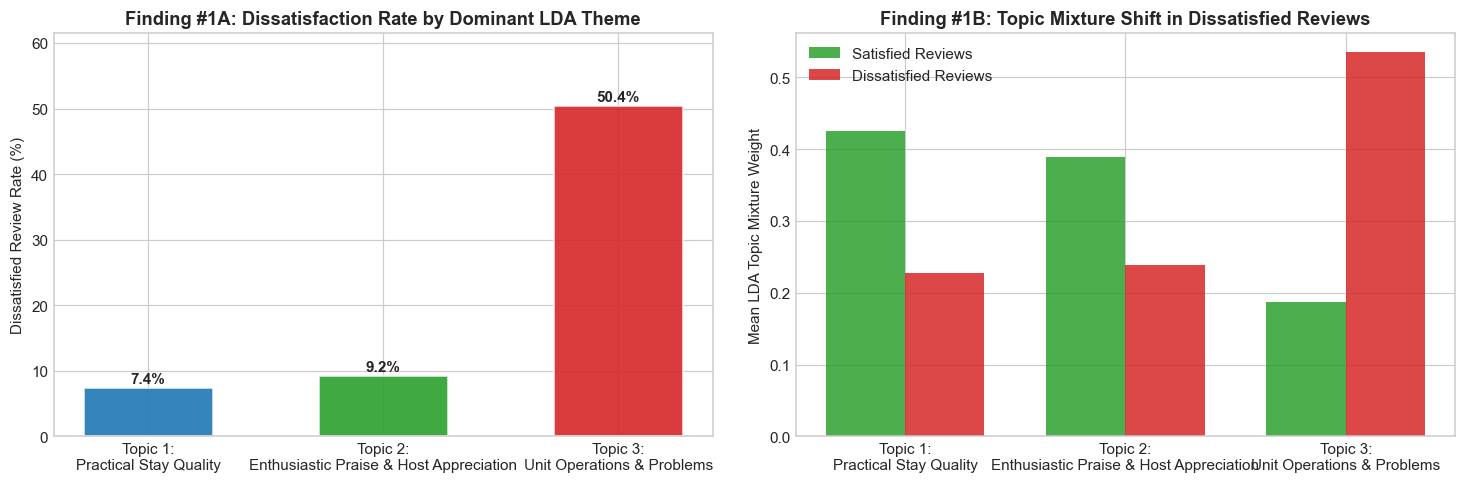

In [18]:
# Step 10 Cross-Analysis Table: LDA Dominant Topic vs Dissatisfaction, Sentiment, Emotions, Ratings, and Top TF-IDF Terms
cross_rows = []
for t_col in topic_cols:
    label = TOPIC_LABELS[t_col]
    mask = (train['Dominant_Topic'] == label).to_numpy()
    sub = train.loc[mask]

    # Compute top 8 distinctive TF-IDF terms inside this LDA topic cluster
    mean_tfidf_in = np.asarray(X_tfidf_train[mask].mean(axis=0)).ravel()
    mean_tfidf_out = np.asarray(X_tfidf_train[~mask].mean(axis=0)).ravel()
    top_tfidf_for_topic = terms[np.argsort(mean_tfidf_in - mean_tfidf_out)[-8:][::-1]]

    cross_rows.append({
        'LDA_Theme': label,
        'Train_Reviews': int(mask.sum()),
        'Share_of_Corpus_%': round(100 * mask.mean(), 1),
        'Dissatisfied_Share_%': round(100 * sub['is_dissatisfied'].mean(), 1),
        'Mean_TextBlob_Polarity': round(sub['TextBlob_Sentiment'].mean(), 3),
        'Mean_Review_Length': round(sub['Review_Length'].mean(), 1),
        'Host_Name_Mention_%': round(100 * sub['mentions_host_name'].mean(), 1),
        'Disgust_per100': round(sub['disgust_per100'].mean(), 2),
        'Anger_per100': round(sub['anger_per100'].mean(), 2),
        'Listing_Cleanliness_Score': round(sub['review_scores_cleanliness'].mean(), 3),
        'Listing_Overall_Rating': round(sub['review_scores_rating'].mean(), 3),
        'Distinctive_TFIDF_Terms (Step 10 Cross-Link)': ', '.join(top_tfidf_for_topic)
    })

cross_analysis_df = pd.DataFrame(cross_rows)
print('=== STEP 10: CROSS-ANALYSIS OF LDA TOPICS WITH TF–IDF, SENTIMENT, EMOTIONS, AND PROPERTY RATINGS ===')
display(cross_analysis_df)

# Visualize Finding #1: Dissatisfaction Rate and Mean Topic Weights in Satisfied vs Dissatisfied Reviews
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

short_labels = [TOPIC_LABELS[c].replace(': ', ':\n') for c in topic_cols]
dissat_rates = cross_analysis_df['Dissatisfied_Share_%'].values
theme_colors = {'Practical': '#1f77b4', 'Praise': '#2ca02c', 'Unit': '#d62728'}
bar_colors = [next(col for key, col in theme_colors.items() if key in TOPIC_LABELS[c]) for c in topic_cols]

axes[0].bar(short_labels, dissat_rates, color=bar_colors, edgecolor='white', width=0.55, alpha=0.9)
for i, v in enumerate(dissat_rates):
    axes[0].text(i, v + 0.8, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].set_ylabel('Dissatisfied Review Rate (%)')
axes[0].set_ylim(0, max(dissat_rates) * 1.22)
axes[0].set_title('Finding #1A: Dissatisfaction Rate by Dominant LDA Theme', fontweight='bold')

sat_topic_means = train.loc[~train['is_dissatisfied'], topic_cols].mean().values
dis_topic_means = train.loc[train['is_dissatisfied'], topic_cols].mean().values
x_idx = np.arange(len(topic_cols))
w = 0.36
axes[1].bar(x_idx - w/2, sat_topic_means, w, label='Satisfied Reviews', color='#2ca02c', alpha=0.85)
axes[1].bar(x_idx + w/2, dis_topic_means, w, label='Dissatisfied Reviews', color='#d62728', alpha=0.85)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(short_labels)
axes[1].set_ylabel('Mean LDA Topic Mixture Weight')
axes[1].set_title('Finding #1B: Topic Mixture Shift in Dissatisfied Reviews', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


### **Empirical Interpretation of Finding #1 (Themes & Dissatisfaction Cross-Analysis):**
- **Evidence:**
  1. **`Topic 3 (Unit Operations & Problems)` is where dissatisfaction concentrates:** 50.4% of training reviews dominated by Topic 3 are flagged as dissatisfied, compared with 9.2% for `Topic 2 (Enthusiastic Praise & Host Appreciation)` and 7.4% for `Topic 1 (Practical Stay Quality)`.
  2. Topic 3 reviews are more than twice as long (88.2 words vs. 40.9 and 38.0), have the lowest polarity (0.203 vs. 0.425 and 0.439), and the highest disgust (0.94 per 100 words vs. 0.13 and 0.22) and anger (1.05 vs. 0.22 and 0.25). Their distinctive TF–IDF terms are physical unit elements and failures (`night`, `bed`, `issue`, `break`, `leave`, `shower`, `dirty`, `room`). They also come from listings with lower overall ratings (4.675 vs. 4.718 and 4.764) and cleanliness scores (4.661 vs. 4.691 and 4.743).
  3. The two positive themes cover most reviews: `Topic 1` (42.4% of training reviews; distinctive terms `perfect`, `helpful`, `location`, `friendly`, `comfortable`, `clean`) and `Topic 2` (36.1%; `beautiful`, `amaze`, `love`, `thank`, `wonderful`, `host_name_token`). Topic 2 has the highest host-name mention rate (37.5% vs. 33.8% and 24.9%) and the highest listing ratings.
- **Interpretation:** Guest dissatisfaction is mainly about the physical unit (bed, shower, bathroom, broken items, cleanliness), while positive reviews either describe practical strengths (location, helpfulness, comfort) or express enthusiastic thanks to the host.
- **Credibility:** (a) The working sample oversamples complaints (14.7% complaint-cue rate vs. 2.1% in the full corpus), so absolute rates such as 50.4% are much higher than in all Toronto reviews; the *ranking* of topics is the meaningful result. (b) The dissatisfaction flag partly uses complaint words such as `dirty`, which also appear in Topic 3. (c) Topics 1 and 2 overlap, and dominant-topic assignment simplifies reviews that mix themes.
- **Implication:** Hosts and Airbnb quality teams should focus on bed, shower, bathroom, maintenance, and cleanliness problems, which are most associated with dissatisfied reviews.

## **6. Deep-Dive Empirical Findings: (A) Property Reviews Changing Over Time & (B) The "Michelin Star" Host Question**

### **6.1 Finding #2: Linking Reviews to Particular Properties (`listing_id`) to Detect Quality Drift Over Time (2010–2026)**

A core motivation in our Team Seven proposal and instructor email is **linking reviews to specific properties (`listing_id`) chronologically so we can observe property reviews changing over time**. Static aggregate ratings on Airbnb (`review_scores_rating`) weight a property's 2017–2021 reviews equally with its 2025–2026 reviews. If a property suffers from "host burnout," deferred maintenance, or handover to a commercial property-management group, its cumulative star rating can remain relatively high even when recent guests report cleanliness and maintenance problems.

We examine this at two levels across our **full 612,856-review English corpus (`df_en`)**:
1. **Macro City-Wide Trajectory (2015–2026):** Annual review volume and dissatisfaction rate across Toronto.
2. **Micro Property-Level Trajectory (`listing_id` Early-Career Half vs. Recent-Career Half):** For all properties with at least 20 English reviews, we sort each property's reviews chronologically by `date` (`rev_rank`), split each property's history into its **Early Half** vs. **Recent Half**, and compute the shift in complaint-cue rate (`Dissat_Shift_Pct_Pts`, in percentage points). `TextBlob` polarity trajectories are then shown for two case-study listings.


=== CITY-WIDE COMPLAINT-CUE RATE BY YEAR (2015-2026) ===


,year,Total_English_Reviews,Active_Reviewed_Listings,Dissatisfaction_Cue_Rate_Pct
0,2015,6009,615,1.43
1,2016,13628,1105,1.39
2,2017,24397,1642,1.27
3,2018,38380,2268,1.69
4,2019,51835,2959,1.65
5,2020,20916,2563,2.09
6,2021,22754,2341,2.11
7,2022,50098,3756,1.95
8,2023,68889,5463,1.98
9,2024,90832,7183,2.06


Listings with at least 20 English reviews: 7,134
=== TOP 5 DETERIORATING TORONTO PROPERTIES (SURGING RECENT COMPLAINTS DESPITE HISTORICAL RATING) ===


,listing_id,name,neighbourhood_cleansed,review_scores_rating,Early_Dissat_%,Recent_Dissat_%,Dissat_Shift_Pct_Pts
1097,19248121,✰Premium 1+1 BR Suite/Parking/ Subway Dir.Access✰,Willowdale East,3.95,0.00,40.00,40.00
2898,53766352,Master bedroom,Agincourt South-Malvern West,3.94,8.33,45.45,37.12
7022,1658975690240484894,Stylish 2BR Condo in the Heart of Downtown Toronto,Waterfront Communities-The Island,4.52,0.00,36.36,36.36
6619,1527909834325091524,Private Room • York Soft Landing• Easy Downtown,Rockcliffe-Smythe,4.45,0.00,33.33,33.33
3939,862549026274623474,Liberty Village Suite,Niagara,4.63,0.00,30.00,30.00



=== TOP 5 TURNAROUND / IMPROVING TORONTO PROPERTIES (EARLY COMPLAINTS RESOLVED IN RECENT HALF) ===


,listing_id,name,neighbourhood_cleansed,review_scores_rating,Early_Dissat_%,Recent_Dissat_%,Dissat_Shift_Pct_Pts
7050,1667043228781986263,Downtown 2BR | CN Tower & Water Views + Parking,Niagara,4.71,30.77,0.0,-30.77
5226,1161872652459209780,Charming 4br w private backyard,Blake-Jones,4.61,30.00,0.0,-30.00
4538,997810555056533240,"Charming Basement Studio, Bathroom, Full Kitchen",The Beaches,4.62,27.78,0.0,-27.78
5117,1143530643398157027,Cityview 2 br/2 bath at Fairview Mall,Don Valley Village,4.65,27.27,0.0,-27.27
6447,1482712718874791739,Modern Stay near Toronto Zoo,Rouge,4.89,23.53,0.0,-23.53


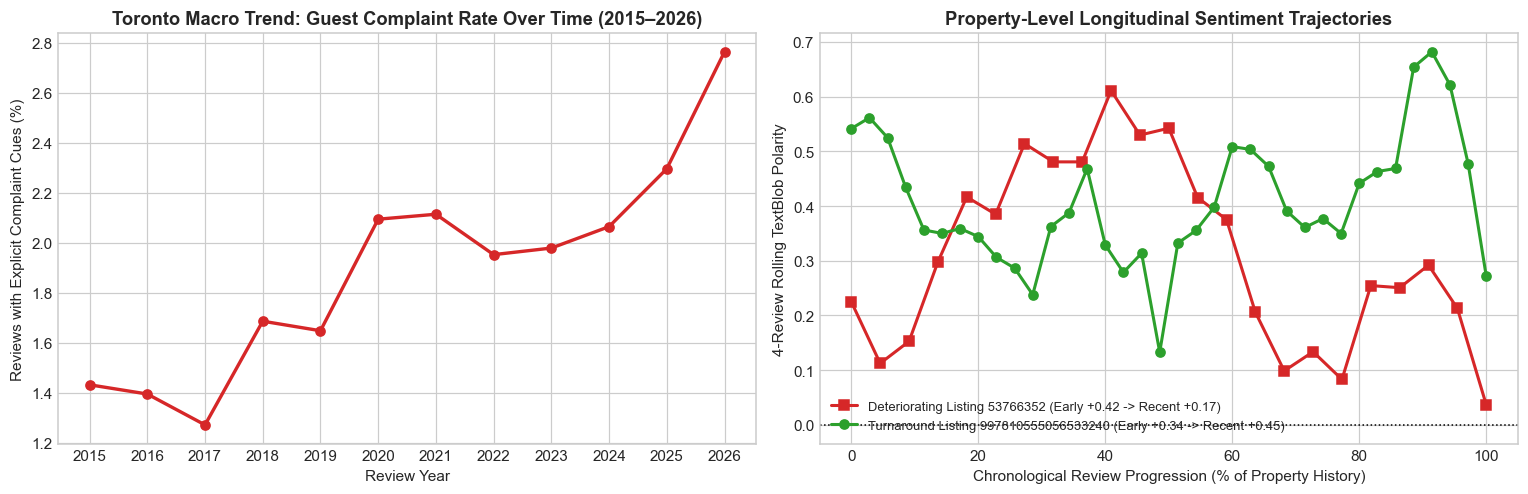

In [19]:
# 1. Macro Annual Trajectory across the full English corpus (2015-2026)
yearly_trends = df_en.loc[df_en['year'] >= 2015].groupby('year').agg(
    Total_English_Reviews=('id', 'count'),
    Active_Reviewed_Listings=('listing_id', 'nunique'),
    Dissatisfaction_Cue_Rate_Pct=('dissatisfied_cue', lambda s: 100 * s.mean())
).reset_index()

# 2. Micro Property-Level Longitudinal Tracking by listing_id (Early Half vs Recent Half of each property's reviews)
df_en_sorted = df_en.sort_values(['listing_id', 'date']).reset_index(drop=True)
df_en_sorted['rev_rank'] = df_en_sorted.groupby('listing_id').cumcount()
df_en_sorted['rev_total'] = df_en_sorted.groupby('listing_id')['id'].transform('count')

multi_rev_props = df_en_sorted.loc[df_en_sorted['rev_total'] >= 20].copy()
multi_rev_props['Career_Half'] = np.where(
    multi_rev_props['rev_rank'] < multi_rev_props['rev_total'] / 2.0,
    'Early_Half', 'Recent_Half'
)

prop_trajectory = multi_rev_props.groupby(
    ['listing_id', 'name', 'host_name', 'neighbourhood_cleansed', 'review_scores_rating', 'Career_Half']
).agg(
    Reviews=('id', 'count'),
    Dissat_Rate=('dissatisfied_cue', 'mean')
).unstack('Career_Half')

prop_trajectory.columns = [f'{col}_{half}' for col, half in prop_trajectory.columns]
prop_trajectory['Dissat_Shift_Pct_Pts'] = 100.0 * (prop_trajectory['Dissat_Rate_Recent_Half'] - prop_trajectory['Dissat_Rate_Early_Half'])
prop_trajectory['Early_Dissat_%'] = 100.0 * prop_trajectory['Dissat_Rate_Early_Half']
prop_trajectory['Recent_Dissat_%'] = 100.0 * prop_trajectory['Dissat_Rate_Recent_Half']
prop_trajectory = prop_trajectory.reset_index()

print('=== CITY-WIDE COMPLAINT-CUE RATE BY YEAR (2015-2026) ===')
display(yearly_trends.round(2))
print(f"Listings with at least 20 English reviews: {prop_trajectory['listing_id'].nunique():,}")

top_deteriorating = prop_trajectory.sort_values('Dissat_Shift_Pct_Pts', ascending=False).head(5)
top_improving = prop_trajectory.sort_values('Dissat_Shift_Pct_Pts', ascending=True).head(5)

print('=== TOP 5 DETERIORATING TORONTO PROPERTIES (SURGING RECENT COMPLAINTS DESPITE HISTORICAL RATING) ===')
display(top_deteriorating[['listing_id', 'name', 'neighbourhood_cleansed', 'review_scores_rating', 'Early_Dissat_%', 'Recent_Dissat_%', 'Dissat_Shift_Pct_Pts']].round(2))

print('\n=== TOP 5 TURNAROUND / IMPROVING TORONTO PROPERTIES (EARLY COMPLAINTS RESOLVED IN RECENT HALF) ===')
display(top_improving[['listing_id', 'name', 'neighbourhood_cleansed', 'review_scores_rating', 'Early_Dissat_%', 'Recent_Dissat_%', 'Dissat_Shift_Pct_Pts']].round(2))

# Plot Macro City-Wide Trend and Micro Property-Level Sentiment Decay Case Studies
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].plot(yearly_trends['year'], yearly_trends['Dissatisfaction_Cue_Rate_Pct'], marker='o', color='#d62728', lw=2.2)
axes[0].set_title('Toronto Macro Trend: Guest Complaint Rate Over Time (2015–2026)', fontweight='bold')
axes[0].set_xlabel('Review Year')
axes[0].set_ylabel('Reviews with Explicit Complaint Cues (%)')
axes[0].set_xticks(yearly_trends['year'])

# Plot rolling review sentiment trajectory for a deteriorating property (53766352) vs turnaround property (997810555056533240)
case_det = df_en_sorted.loc[df_en_sorted['listing_id'] == 53766352].copy()
case_det['Polarity'] = case_det['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
case_det['Rolling_Polarity'] = case_det['Polarity'].rolling(4, min_periods=1).mean()
case_det['Review_Order_Pct'] = np.linspace(0, 100, len(case_det))

case_imp = df_en_sorted.loc[df_en_sorted['listing_id'] == 997810555056533240].copy()
case_imp['Polarity'] = case_imp['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
case_imp['Rolling_Polarity'] = case_imp['Polarity'].rolling(4, min_periods=1).mean()
case_imp['Review_Order_Pct'] = np.linspace(0, 100, len(case_imp))

def half_means(d):
    h = len(d) // 2
    return d['Polarity'].iloc[:h].mean(), d['Polarity'].iloc[h:].mean()
det_early, det_recent = half_means(case_det)
imp_early, imp_recent = half_means(case_imp)

axes[1].plot(case_det['Review_Order_Pct'], case_det['Rolling_Polarity'], marker='s', color='#d62728', lw=2,
             label=f'Deteriorating Listing 53766352 (Early {det_early:+.2f} -> Recent {det_recent:+.2f})')
axes[1].plot(case_imp['Review_Order_Pct'], case_imp['Rolling_Polarity'], marker='o', color='#2ca02c', lw=2,
             label=f'Turnaround Listing 997810555056533240 (Early {imp_early:+.2f} -> Recent {imp_recent:+.2f})')
axes[1].axhline(0, color='black', linestyle=':', lw=1)
axes[1].set_title('Property-Level Longitudinal Sentiment Trajectories', fontweight='bold')
axes[1].set_xlabel('Chronological Review Progression (% of Property History)')
axes[1].set_ylabel('4-Review Rolling TextBlob Polarity')
axes[1].legend(loc='lower left', fontsize=8.5)

plt.tight_layout()
plt.show()


In [20]:
# Inspect actual Early vs. Recent review texts on Deteriorating Listing 53766352 and Downtown Condo 1658975690240484894
for lid in [53766352, 1658975690240484894]:
    prop_sub = df_en_sorted.loc[df_en_sorted['listing_id'] == lid].copy()
    prop_sub['Polarity'] = prop_sub['comments'].map(lambda t: TextBlob(str(t)).sentiment.polarity)
    half = len(prop_sub) // 2
    print(f'=== Longitudinal Case Study: Listing {lid} ("{prop_sub["name"].iloc[0]}") | Cumulative Rating: {prop_sub["review_scores_rating"].iloc[0]} ===')
    print(f'    Early-Half Mean Polarity: {prop_sub.iloc[:half]["Polarity"].mean():+.3f} | Recent-Half Mean Polarity: {prop_sub.iloc[half:]["Polarity"].mean():+.3f}')
    early_ex = prop_sub.iloc[0]
    recent_neg = prop_sub.iloc[half:].loc[prop_sub.iloc[half:]['dissatisfied_cue']].tail(1).iloc[0]
    print(f'  [EARLY  - {early_ex["date"].strftime("%Y-%m-%d")}] (Polarity={early_ex["Polarity"]:+.3f}): {early_ex["comments"][:220]}')
    print(f'  [RECENT - {recent_neg["date"].strftime("%Y-%m-%d")}] (Polarity={recent_neg["Polarity"]:+.3f}): {recent_neg["comments"][:220]}\n')


=== Longitudinal Case Study: Listing 53766352 ("Master bedroom") | Cumulative Rating: 3.94 ===
    Early-Half Mean Polarity: +0.421 | Recent-Half Mean Polarity: +0.166
  [EARLY  - 2022-05-15] (Polarity=+0.225): Room was similar to photos and clean! Had a short stay so it was decent, host was attentive and helpful!
  [RECENT - 2023-09-04] (Polarity=-0.272): Kitsches wasn’t clean , fridge smell very bad

=== Longitudinal Case Study: Listing 1658975690240484894 ("Stylish 2BR Condo in the Heart of Downtown Toronto") | Cumulative Rating: 4.52 ===
    Early-Half Mean Polarity: +0.502 | Recent-Half Mean Polarity: +0.347
  [EARLY  - 2026-05-03] (Polarity=+0.500): Great place, really close to everything would stay again😊
  [RECENT - 2026-08-23] (Polarity=-0.191): Well situated. It was not terrribly dirty, but also not very clean, mainly the bathroom and kitchen.



### **Empirical Interpretation of Finding #2 (Property Reviews Changing Over Time):**
- **Evidence:**

  1. **City-wide context:** the share of English reviews containing complaint cues is low but rising, from 1.3–1.7% in 2015–2019 to about 2.0–2.1% in 2020–2024, 2.3% in 2025, and 2.8% in 2026 (January–September only). Review volume also grew sharply (6,009 reviews in 2015 vs. 114,105 in 2026), so this trend may partly reflect a changing mix of listings and guests.
  2. Among the 7,134 listings with at least 20 English reviews, some show large increases in the complaint-cue rate between the early and recent halves of their review history: listing 19248121 (0% → 40%), 53766352 (8.3% → 45.5%), and 1658975690240484894 (0% → 36.4%). Others improve: 1667043228781986263 (30.8% → 0%), 1161872652459209780 (30.0% → 0%), and 997810555056533240 (27.8% → 0%).
  3. Representative texts confirm the shift. For listing 53766352, mean polarity falls from +0.421 (early half) to +0.166 (recent half); an early review says *"Room was similar to photos and clean!"* while a recent one says *"Kitchen wasn't clean, fridge smell very bad."* For listing 1658975690240484894 (cumulative rating 4.52), polarity falls from +0.502 to +0.347, and a recent review says *"not terribly dirty, but also not very clean, mainly the bathroom and kitchen."*
- **Interpretation:** Reading reviews in time order can reveal changes that a single lifetime rating does not show. Three of the five most-deteriorating listings still have cumulative ratings of 4.45–4.63. The other two (3.94–3.95) already have low ratings, so for them the cumulative score does reflect the problems.
- **Credibility:** (a) With 20 reviews, each half has about 10 reviews, so one or two complaints change the rate by 10–20 percentage points; picking the most extreme listings exaggerates real change (regression to the mean). (b) "Early" and "recent" are halves of each listing's review sequence, not fixed calendar periods; listing 1658975690240484894's whole history falls within 2026. (c) The complaint-cue lexicon is a simple keyword measure.
- **Implication:** Airbnb could monitor rolling recent-review complaint rates per listing, and guests should read the most recent reviews rather than relying only on the lifetime average.

### **6.2 Finding #3: The "Michelin Star" Question — How Relevant Is Guest–Host Interaction to the Rating of an Airbnb Listing?**

In our Team Seven proposal, we posed the **"Michelin Star Question"**: *Just as Michelin inspectors weigh whether service and chef hospitality matter alongside food on the plate, how relevant is a guest's personal interaction with the host to the rating of an Airbnb listing compared to physical property attributes?*

Because we normalized every host's name and nickname into `host_name_token` (**Steps 4 & 7**) and linked all 6 property sub-ratings from `listings.csv` (**Step 2**), we can test this question through two complementary empirical checks:
1. **Textual Host-Interaction Check (`mentions_host_name`):** Compare reviews that explicitly mention the host by name (`host_name_token` present, about one-third of training reviews; exact share printed in Section 2) against reviews that never mention the host's name.
2. **Multi-Attribute Sub-Score Check ($N = 17,763$ Toronto Listings):** Compare Pearson correlations ($r$) and standardized multiple-regression beta weights ($\beta$) of all 6 sub-ratings (`accuracy`, `value`, `cleanliness`, `communication`, `checkin`, `location`) predicting overall `review_scores_rating`.


=== FINDING #3A: TEXTUAL HOST INTERACTION EFFECT (MENTIONING HOST_NAME_TOKEN IN REVIEW) ===


,No_Host_Name_Mention (0),Mentions_Host_by_Name (1),Difference (Host_Mention - No_Mention)
Review_Count,1281.000,638.000,-643.000
Dissatisfied_Rate_Pct,18.345,15.204,-3.141
Mean_TextBlob_Polarity,0.387,0.373,-0.014
Trust_per100,6.557,5.540,-1.017
Joy_per100,5.319,4.154,-1.165
Anger_per100,0.463,0.301,-0.163
Disgust_per100,0.390,0.229,-0.161
Listing_Comm_Rating,4.838,4.887,0.049
Listing_Cleanliness,4.683,4.743,0.059
Listing_Overall_Rating,4.703,4.770,0.067



=== FINDING #3B: STRUCTURAL SUB-SCORE DRIVERS OF OVERALL RATING (N = 17,763 LISTINGS, R² = 0.839) ===


,Rating_Dimension,Domain_Role,Pearson_r_with_Overall,Standardized_Beta_Weight
0,Value (Price vs Quality),Economic Value,0.8413,0.2793
1,Accuracy (Photos/Description),Physical / Expectation,0.8466,0.2738
2,Host Communication (Interaction),Host Interaction (Michelin Question),0.7758,0.2014
3,Cleanliness (Hygiene),Physical Hygiene Floor,0.7847,0.1990
4,Check-In Process,Host / Logistics,0.6927,0.0471
5,Neighborhood Location,External Geography,0.6048,0.0446


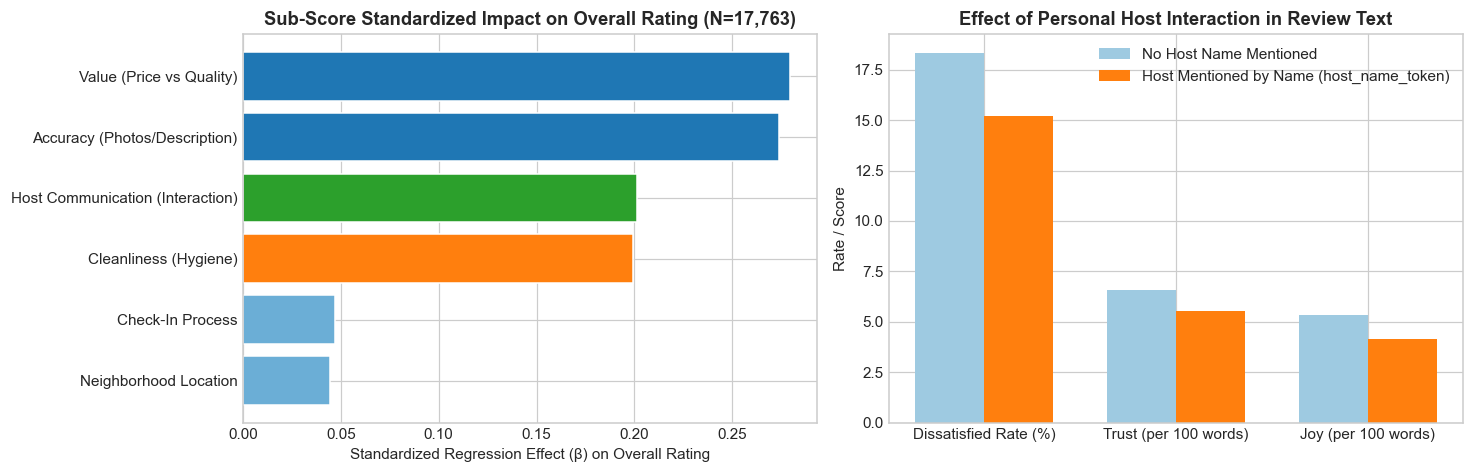

In [21]:
# 1. Textual Host-Interaction Comparison on Training Reviews (Mentions Host Name vs Does Not)
host_interaction_summary = train.groupby('mentions_host_name').agg(
    Review_Count=('id', 'count'),
    Dissatisfied_Rate_Pct=('is_dissatisfied', lambda s: 100 * s.mean()),
    Mean_TextBlob_Polarity=('TextBlob_Sentiment', 'mean'),
    Trust_per100=('trust_per100', 'mean'),
    Joy_per100=('joy_per100', 'mean'),
    Anger_per100=('anger_per100', 'mean'),
    Disgust_per100=('disgust_per100', 'mean'),
    Listing_Comm_Rating=('review_scores_communication', 'mean'),
    Listing_Cleanliness=('review_scores_cleanliness', 'mean'),
    Listing_Overall_Rating=('review_scores_rating', 'mean')
).T
host_interaction_summary.columns = ['No_Host_Name_Mention (0)', 'Mentions_Host_by_Name (1)']
host_interaction_summary['Difference (Host_Mention - No_Mention)'] = (
    host_interaction_summary['Mentions_Host_by_Name (1)'] - host_interaction_summary['No_Host_Name_Mention (0)']
)
print('=== FINDING #3A: TEXTUAL HOST INTERACTION EFFECT (MENTIONING HOST_NAME_TOKEN IN REVIEW) ===')
display(host_interaction_summary.round(3))

# 2. Structural Sub-Rating Comparison across all 17,763 Rated Toronto Listings in listings.csv
subscore_cols = [
    'review_scores_accuracy', 'review_scores_value', 'review_scores_cleanliness',
    'review_scores_communication', 'review_scores_checkin', 'review_scores_location'
]
clean_listings = listings_raw.dropna(subset=['review_scores_rating'] + subscore_cols).copy()
X_sub = clean_listings[subscore_cols]
y_sub = clean_listings['review_scores_rating']

# Standardized regression beta weights to isolate each dimension's marginal contribution to overall rating
X_sub_std = (X_sub - X_sub.mean()) / X_sub.std()
y_sub_std = (y_sub - y_sub.mean()) / y_sub.std()
sub_reg = LinearRegression().fit(X_sub_std, y_sub_std)

michelin_df = pd.DataFrame({
    'Rating_Dimension': ['Accuracy (Photos/Description)', 'Value (Price vs Quality)', 'Cleanliness (Hygiene)',
                         'Host Communication (Interaction)', 'Check-In Process', 'Neighborhood Location'],
    'Domain_Role': ['Physical / Expectation', 'Economic Value', 'Physical Hygiene Floor',
                    'Host Interaction (Michelin Question)', 'Host / Logistics', 'External Geography'],
    'Pearson_r_with_Overall': [clean_listings['review_scores_rating'].corr(clean_listings[c]) for c in subscore_cols],
    'Standardized_Beta_Weight': sub_reg.coef_
}).sort_values('Standardized_Beta_Weight', ascending=False).reset_index(drop=True)

print(f'\n=== FINDING #3B: STRUCTURAL SUB-SCORE DRIVERS OF OVERALL RATING (N = {len(clean_listings):,} LISTINGS, R² = {sub_reg.score(X_sub_std, y_sub_std):.3f}) ===')
display(michelin_df.round(4))

# Plot the Michelin Star Comparison
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

axes[0].barh(michelin_df['Rating_Dimension'][::-1], michelin_df['Standardized_Beta_Weight'][::-1],
             color=['#6baed6', '#6baed6', '#ff7f0e', '#2ca02c', '#1f77b4', '#1f77b4'], edgecolor='white')
axes[0].set_xlabel('Standardized Regression Effect (β) on Overall Rating')
axes[0].set_title('Sub-Score Standardized Impact on Overall Rating (N=17,763)', fontweight='bold')

metrics_labels = ['Dissatisfied Rate (%)', 'Trust (per 100 words)', 'Joy (per 100 words)']
no_host_vals = [
    host_interaction_summary.loc['Dissatisfied_Rate_Pct', 'No_Host_Name_Mention (0)'],
    host_interaction_summary.loc['Trust_per100', 'No_Host_Name_Mention (0)'],
    host_interaction_summary.loc['Joy_per100', 'No_Host_Name_Mention (0)']
]
yes_host_vals = [
    host_interaction_summary.loc['Dissatisfied_Rate_Pct', 'Mentions_Host_by_Name (1)'],
    host_interaction_summary.loc['Trust_per100', 'Mentions_Host_by_Name (1)'],
    host_interaction_summary.loc['Joy_per100', 'Mentions_Host_by_Name (1)']
]
x_m = np.arange(len(metrics_labels))
axes[1].bar(x_m - 0.18, no_host_vals, 0.36, label='No Host Name Mentioned', color='#9ecae1')
axes[1].bar(x_m + 0.18, yes_host_vals, 0.36, label='Host Mentioned by Name (host_name_token)', color='#ff7f0e')
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(metrics_labels)
axes[1].set_ylabel('Rate / Score')
axes[1].set_title('Effect of Personal Host Interaction in Review Text', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()


### **Empirical Interpretation of Finding #3 (Answering the "Michelin Star" Host Question):**
- **Evidence:**
  1. **Mentioning the host by name is associated with fewer complaints and slightly higher listing ratings:** reviews that mention the host (`host_name_token`) have a lower dissatisfaction rate (15.2% vs. 18.3%) and come from listings with slightly higher overall (4.770 vs. 4.703), communication (4.887 vs. 4.838), and cleanliness (4.743 vs. 4.683) scores.
  2. **But host mentions do not come with more positive emotion words:** polarity is almost identical (0.373 vs. 0.387), and trust (5.54 vs. 6.56 per 100 words) and joy (4.15 vs. 5.32) rates are actually *lower*. One possible explanation is that reviews naming the host are longer, which dilutes per-100-word emotion rates compared with short reviews such as "Great place!".
  3. **Across 17,763 listings (R² = 0.839), expectation-related sub-scores have the largest standardized coefficients:** Value (β = 0.279, r = 0.841) and Accuracy (β = 0.274, r = 0.847), followed by Host Communication (β = 0.201, r = 0.776) and Cleanliness (β = 0.199, r = 0.785), which are essentially tied. Check-in (0.047) and Location (0.045) add little once the others are included.
- **Interpretation ("Michelin Star" answer):** Host interaction matters about as much as cleanliness for a listing's overall rating, but both are behind *meeting expectations* — fair value and an accurate listing. A personal host relationship is associated with fewer complaints, but it does not replace an accurately described, good-value unit.
- **Credibility:** (a) These are associations, not causal effects. (b) Sub-scores are highly correlated with each other and come from the same guests, so the β weights are unstable and should be compared only roughly. (c) Host-name matching can miss hosts mentioned as "the host" and can miss unusual nicknames.
- **Implication:** Hosts should first make sure the listing is accurate and fairly priced, keep the unit clean, and communicate personally; none of these alone explains high ratings.


## **7. Predictive Modeling of Property Ratings from Review Text (Course Validation Protocol)**

Following **`05_Text_Features_and_Rating_Prediction`** and **Part V of `Assignment #2`**, we test whether progressively richer text-mining features improve predictions of a listing's rating (`review_scores_rating`) over a deployable training-mean baseline (`DummyRegressor(strategy='mean')`):

1. **Mean baseline:** Always predicts the training partition's mean rating.
2. **Model 1 — `Sentiment`:** `TextBlob_Sentiment` only (1 feature).
3. **Model 2 — `Sentiment + emotions + length`:** Adds `Review_Length` and all 8 normalized NRC emotion rates (`EMOTION_COLS`, 10 features).
4. **Model 3 — `Sentiment + emotions + length + host/negation + topics`:** Adds our domain-engineered features (`mentions_host_name`, `negation_count`) plus $K - 1 = 2$ LDA topic weights (`Topic_1`, `Topic_2`, 14 features). *Note:* Because the $K = 3$ topic weights sum to $1.0$ for every row, including all $K$ weights alongside an intercept would create exact linear dependence (perfect multicollinearity); omitting `Topic_3` treats it as the reference baseline.
5. **Model 4 — `Full Cross-Analyzed Hybrid (+ TF-IDF SVD)`:** Adds the 10 `TruncatedSVD` TF–IDF components (`SVD_1`..`SVD_10`, 24 features) to evaluate the combined predictive power of **Step 10's cross-analysis (TF–IDF/SVD + LDA + Sentiment/Emotions)**.

We select the winning model strictly by **lowest Validation MAE** before unlocking the held-out `test` partition.


In [22]:
# Assemble feature matrices for train, validation, and test partitions
extra_cols = ['mentions_host_name', 'negation_count']
X_train = base_train.join(train[extra_cols]).join(topic_train).join(svd_train_df)
X_valid = base_valid.join(valid[extra_cols]).join(topic_valid).join(svd_valid_df)
X_test = base_test.join(test[extra_cols]).join(topic_test).join(svd_test_df)

feature_sets = {
    'Sentiment': ['TextBlob_Sentiment'],
    'Sentiment + emotions + length': ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS,
    'Sentiment + emotions + length + host/neg + topics':
        ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS + extra_cols + topic_cols[:-1],
    'Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD)':
        ['TextBlob_Sentiment', 'Review_Length'] + EMOTION_COLS + extra_cols + topic_cols[:-1] + svd_cols
}

assert X_train.index.equals(train.index) and X_valid.index.equals(valid.index) and X_test.index.equals(test.index)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_valid.to_numpy()).all()

models, comparison_rows = {}, []
baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(train), 1)), train['review_scores_rating'])

for name in ['Mean baseline'] + list(feature_sets):
    if name == 'Mean baseline':
        model = baseline
        a, b = np.zeros((len(train), 1)), np.zeros((len(valid), 1))
    else:
        cols = feature_sets[name]
        a, b = X_train[cols], X_valid[cols]
        model = LinearRegression().fit(a, train['review_scores_rating'])
    models[name] = model
    for split_name, X_split, y_split in [
        ('Training', a, train['review_scores_rating']),
        ('Validation', b, valid['review_scores_rating'])
    ]:
        comparison_rows.append({
            'Model': name,
            'Split': split_name,
            **metrics(y_split, model.predict(X_split))
        })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

validation_results = comparison.query("Split == 'Validation'").sort_values('MAE', kind='stable')
selected_name = validation_results.iloc[0]['Model']
print('Selected by lowest Validation MAE:', selected_name)


,Model,Split,MAE,MSE,R2
0,Mean baseline,Training,0.1991,0.0625,0.0000
1,Mean baseline,Validation,0.2160,0.0852,-0.0036
2,Sentiment,Training,0.1988,0.0622,0.0048
3,Sentiment,Validation,0.2148,0.0838,0.0119
4,Sentiment + emotions + length,Training,0.1976,0.0618,0.0119
5,Sentiment + emotions + length,Validation,0.2145,0.0827,0.0254
6,Sentiment + emotions + length + host/neg + topics,Training,0.1919,0.0599,0.0426
7,Sentiment + emotions + length + host/neg + topics,Validation,0.2094,0.0795,0.0635
8,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),Training,0.1870,0.0579,0.0731
9,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),Validation,0.2064,0.0800,0.0573


Selected by lowest Validation MAE: Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD)


### **7.1 Final Held-Out Test Evaluation & Error Analysis**

Following **Section 6 of `05_Text_Features_and_Rating_Prediction`**, we now freeze `chosen_k = 3` and `selected_name`, refit the chosen linear regression model on the combined development data (`train + valid`) while keeping the training-fitted text vectorizers, SVD, and LDA frozen, and evaluate **once** on the held-out `test` set, whose listings were never seen during development. We also inspect the 5 largest prediction errors on `test`.


In [23]:
# Refit the validation-selected regression model on dev (train + valid) and evaluate once on held-out test
X_dev = pd.concat([X_train, X_valid]).sort_index()
y_dev = df.loc[X_dev.index, 'review_scores_rating']
y_test = test['review_scores_rating']

final_baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(y_dev), 1)), y_dev)
baseline_test_pred = final_baseline.predict(np.zeros((len(test), 1)))

selected_cols = feature_sets[selected_name]
final_model = LinearRegression().fit(X_dev[selected_cols], y_dev)
final_test_pred = final_model.predict(X_test[selected_cols])

# Evaluate ONLY the development-mean baseline and the validation-selected model, once
test_results = pd.DataFrame([
    {'Model': 'Mean baseline', **metrics(y_test, baseline_test_pred)},
    {'Model': selected_name, **metrics(y_test, final_test_pred)}
])
print(f'=== FINAL HELD-OUT TEST EVALUATION (N = {len(test):,} REVIEWS FROM {test["listing_id"].nunique():,} UNSEEN LISTINGS) ===')
display(test_results.round(4))

out_of_bounds = int(((final_test_pred < 1.0) | (final_test_pred > 5.0)).sum())
print(f'Predictions outside 1.0–5.0 bounds: {out_of_bounds}')

# Inspect the 5 largest absolute prediction errors on the held-out test set
error_review = test[['listing_id', 'host_name', 'review_scores_rating', 'TextBlob_Sentiment', 'comments']].copy()
error_review['Predicted_Rating'] = final_test_pred
error_review['Absolute_Error'] = (error_review['review_scores_rating'] - final_test_pred).abs()

print('\nTop 5 Largest Prediction Errors on Held-Out Test Set:')
with pd.option_context('display.max_colwidth', 240):
    display(error_review.nlargest(5, 'Absolute_Error').round(3))


=== FINAL HELD-OUT TEST EVALUATION (N = 601 REVIEWS FROM 454 UNSEEN LISTINGS) ===


,Model,MAE,MSE,R2
0,Mean baseline,0.1991,0.0668,-0.0000
1,Full Hybrid (Sentiment + emotions + host/neg + LDA + TF-IDF SVD),0.1908,0.0631,0.0558


Predictions outside 1.0–5.0 bounds: 0

Top 5 Largest Prediction Errors on Held-Out Test Set:


,listing_id,host_name,review_scores_rating,TextBlob_Sentiment,comments,Predicted_Rating,Absolute_Error
row_id,,,,,,,
425,1767546045657876354,Brooke,3.00,-0.037,"I wanted to start off by saying that Brooke communicated very well and her instructions were very organized. This condo is a corner suite and has a beautiful view, however, that is about it. I have stayed at many airbnb’s in the past an...",4.699,1.699
1727,826867995203115686,Amir,3.00,-0.178,"Don’t let the photos fool you, this is a facade. Dirty soiled furniture, terrible amenities including cheap beds and sheets, 3 bath towels for my family of 6 over 3 nights, a dishwasher but no pucks/soap….the list goes on. TV not workin...",4.513,1.513
2014,584104257121855339,Marta,3.50,0.700,"great place in a great location, marta was a lovely host.",4.820,1.320
2133,1647303900760968867,Tsering,3.78,0.583,Great host. Clean space with ample room.,4.712,0.932
898,23504433,Mohamed,3.86,0.660,Mohamed was a great host who was very attentive and helpful. Would reccomend his place to anyone.,4.752,0.892


### **Interpretation of Predictive Modeling & Largest Errors:**
1. **Validation comparison (used for selection; validation listings are unseen in training):**
   - Mean baseline: Validation MAE = 0.2160.
   - `Sentiment` alone: 0.2148 — almost no improvement.
   - `+ emotions + length`: 0.2145.
   - `+ host/negation + topics`: 0.2094 ($R^2 = 0.064$) — the largest single improvement.
   - **`Full Hybrid (+ TF-IDF SVD)`**: **0.2064** ($R^2 = 0.057$), the lowest validation MAE, so it was selected (our pre-set criterion) and frozen with $K = 3$ before touching the test set. Its validation $R^2$ is slightly below the previous model's, so the 10 SVD components help MAE but not squared error.
2. **Held-out test (evaluated once, 601 reviews from 454 listings never seen during development):** The selected Full Hybrid model reached **Test MAE = 0.1908, MSE = 0.0631, $R^2$ = 0.056**, compared with the development-mean baseline's **MAE = 0.1991, MSE = 0.0668** ($R^2 \approx 0$). That is an improvement of about 0.008 stars (≈4%) — real but small. No predictions fell outside 1–5.
3. **Why the gain is small, and what the largest errors reveal:**
   - `review_scores_rating` is a **listing-level lifetime average**, not the rating of the individual review, and it is compressed near 5. Short positive reviews of lower-rated listings are common large errors, e.g., *"great place in a great location, marta was a lovely host"* on a listing rated 3.50 (predicted 4.82). A single review cannot reveal other guests' bad experiences.
   - The model also under-reacts to complaints, especially polite ones: *"Brooke communicated very well… This condo… has a beautiful view, however, that is about it"* (polarity −0.037) was predicted 4.70 for a listing rated 3.00, and *"Don't let the photos fool you, this is a facade. Dirty soiled furniture…"* (polarity −0.178) was predicted 4.51 for another listing rated 3.00. Predictions stay close to the mean because most training ratings are near 5.
   - Because the split is by listing, every test review comes from a listing the model never saw during development, so the test result reflects performance on new listings.

## **8. Credibility Checks, Limitations, Decision Recommendations, and References**

### **8.1 Credibility Checks & Methodological Limitations**
1. **Observed Associations vs. Causal Claims:** Our regression and cross-tabulation findings establish **predictive and descriptive associations** in post-stay review text, not causal treatment effects. While mentioning the host by name (`host_name_token`) is associated with slightly higher listing ratings (+0.067) and a lower dissatisfaction rate (15.2% vs. 18.3%), we cannot claim that a host repeating their name to guests would raise ratings.
2. **Property-Level vs. Review-Level Rating Granularity:** Inside Airbnb provides `review_scores_rating` at the `listing_id` level rather than per individual review row. We partly addressed this limitation by constructing review-level dissatisfaction indicators (`TextBlob_Sentiment < 0.05` and negation/complaint tokens) and tracking longitudinal shifts within the same `listing_id` over time.
3. **Survivorship Bias & Rating Inflation:** Delisted properties vanish from the September 2026 snapshot, and bilateral rating visibility compresses surviving ratings (median 4.88, mean 4.84).
4. **Lexical & English-Only Scope Constraints:** Dropping 77,107 reviews flagged as non-English by an approximate rule-based filter (**Step 1**) prevented translation artifacts in `TextBlob` and `NRCLex`, but means our findings reflect English-speaking guests and may under-represent international tourist segments. Furthermore, lexicon-based tools remain vulnerable to sarcasm, irony, and polysemy.
5. **Sampling and Measurement:** The working sample oversamples low-rated and complaint reviews (40% of the sample; complaint-cue rate 14.7% vs. 2.1% in the full corpus), so dissatisfaction rates describe the sample, not all Toronto reviews. The dissatisfaction flag is partly defined by polarity and complaint words, so comparisons on those same measures are partly circular.
6. **Listing-Level Split:** Train, validation, and test are split by listing (no listing appears in two partitions), so test results reflect new listings. This is stricter than a random review-level split; the cost is that partition sizes are set by whole listings (1,919 / 480 / 601 reviews).

---

### **8.2 Actionable Recommendations for Stakeholders**

| Stakeholder | Empirical Finding Used | Concrete Recommended Action |
|---|---|---|
| **Airbnb Platform (Quality & Search Product)** | **Finding #1 & Finding #2:** `Topic 3` (Unit Operations & Problems) reviews are 50.4% dissatisfied vs. 9.2% (Enthusiastic Praise) and 7.4% (Practical Stay Quality) in our sample; some listings show +30 to +40 point increases in recent complaint rates while still rated 4.45–4.63. | **1. Rolling Recent-Review Health Score:** Track recent review polarity and complaint tokens (`not_clean`, `not_work`, `smell`, `stain`) per listing to prioritize quality checks.<br>**2. Multi-Word Negation Search Tags:** Upgrade Airbnb's single-word review search filter so `clean` does not match `"not clean"`. |
| **Toronto Hosts (Property Management)** | **Finding #1 & Finding #3 (Michelin Star Question):** Value (β = 0.279) and Accuracy (β = 0.274) have the largest associations with overall rating, with Communication (0.201) and Cleanliness (0.199) about equal; reviews naming the host are less often dissatisfied (15.2% vs. 18.3%). | **1. Set Accurate Expectations and Maintain the Unit:** Keep photos, descriptions, and price consistent with the actual unit, and check bathroom cleanliness, odors, bed comfort, and kitchen equipment before every arrival.<br>**2. Personalize Host Communication:** Send a personalized check-in message using your first name (`host_name`) and follow up within the first evening to resolve minor issues before checkout. |
| **Customers / Guests (Booking Strategy)** | **Finding #2 (Longitudinal Drift):** Some listings' recent reviews contain far more complaints than their earlier reviews, while their lifetime rating stays in the mid-4s. | **Sort Reviews by "Most Recent":** Ignore the headline $4.7+$ average until reading the 5 most recent reviews specifically for `Topic 3` unit-operation red flags (`smell`, `dirty`, `noise`, `not working`, or commercial multi-listing neglect). |

---

### **8.3 References**
- **Dataset Source:** Inside Airbnb: Toronto (Sep 2026), curated on Kaggle by Vladimir Kondratev: [https://www.kaggle.com/datasets/vladimirkondratev/inside-airbnb-toronto-sep-2026](https://www.kaggle.com/datasets/vladimirkondratev/inside-airbnb-toronto-sep-2026) (Original public data from [Inside Airbnb](https://insideairbnb.com/) under CC BY 4.0 license).
- **Course Materials:** Sim, J. (2026). *OPIM 5671 Data Mining and Time Series Forecasting: Lectures 08–10 & Hands-On Notebooks 04–06*. University of Connecticut.
- **Sentiment Analysis:** Loria, S. (2018). *TextBlob: Simplified Text Processing*. [https://textblob.readthedocs.io/](https://textblob.readthedocs.io/)
- **Emotion Lexicon:** Mohammad, S. M., & Turney, P. D. (2013). Crowdsourcing a Word–Emotion Association Lexicon. *Computational Intelligence*, 29(3), 436–465. (`NRCLex 4.1.0`).
- **Topic Modeling & Coherence:** Blei, D. M., Ng, A. Y., & Jordan, M. I. (2003). Latent Dirichlet Allocation. *Journal of Machine Learning Research*, 3, 993–1022; Mimno, D., Wallach, H., Talley, E., Leenders, M., & McCallum, A. (2011). Optimizing Semantic Coherence in Topic Models. *EMNLP*, 262–272.
